## Окружение

Создайте окружение `sc_pbmc` в терминале Linux (или терминале JupyterLab) и зарегистрируйте его как ядро Jupyter. `scikit-misc` необходим для отбора HVG методом `seurat_v3`.

```bash
mamba create -n sc_pbmc -c conda-forge python=3.11 scanpy scikit-misc jupyterlab ipykernel -y
mamba activate sc_pbmc
python -m ipykernel install --user --name sc_pbmc --display-name "sc_pbmc"
```

Выберите ядро **Python (sc_pbmc)**. Если `mamba` отсутствует, замените `mamba create` на `conda create`.

## Данные

**PBMC 3k** — клетки периферической крови здорового донора, секвенированные с помощью 10x Genomics (около 2700 клеток). Ниже скачивается исходная матрица UMI counts в формате Matrix Market, включая файлы генов и клеточных штрихкодов. После распаковки они окажутся в `data/filtered_gene_bc_matrices/hg19/`.

Источник: [10x Genomics — PBMC 3k](https://www.10xgenomics.com/datasets/3-k-pbm-cs-from-a-healthy-donor-1-standard-1-0-0) · [документация Scanpy](https://scanpy.readthedocs.io/en/latest/api/generated/scanpy.datasets.pbmc3k.html).

In [ ]:
!mkdir -p data
!curl -fL https://cf.10xgenomics.com/samples/cell-exp/1.1.0/pbmc3k/pbmc3k_filtered_gene_bc_matrices.tar.gz -o data/pbmc3k.tar.gz
!tar -xzf data/pbmc3k.tar.gz -C data

In [2]:
import scanpy as sc
import matplotlib.pyplot as plt
import numpy as np

In [3]:
adata = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")

In [4]:
adata

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)

In [5]:
adata.var

,gene_ids
MIR1302-10,ENSG00000243485
FAM138A,ENSG00000237613
OR4F5,ENSG00000186092
RP11-34P13.7,ENSG00000238009
RP11-34P13.8,ENSG00000239945
...,...
AC145205.1,ENSG00000215635
BAGE5,ENSG00000268590
CU459201.1,ENSG00000251180
AC002321.2,ENSG00000215616


In [6]:
adata.var["mt"] = adata.var_names.str.startswith("MT-")

In [7]:
adata.var

,gene_ids,mt
MIR1302-10,ENSG00000243485,False
FAM138A,ENSG00000237613,False
OR4F5,ENSG00000186092,False
RP11-34P13.7,ENSG00000238009,False
RP11-34P13.8,ENSG00000239945,False
...,...,...
AC145205.1,ENSG00000215635,False
BAGE5,ENSG00000268590,False
CU459201.1,ENSG00000251180,False
AC002321.2,ENSG00000215616,False


In [8]:
adata.var_names[adata.var["mt"]]

Index(['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3',
       'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB'],
      dtype='str')

# Какие есть ещё поля в AnnData? 

## Структура AnnData

Основная матрица имеет размер:

$$
\underbrace{C}_{\text{клетки}}
\times
\underbrace{G}_{\text{гены}}
$$

- **Строки** — клетки (observations).
- **Столбцы** — гены (variables).
- **Элементы** — значения экспрессии генов в клетках.

Здесь `adata.X` — название поля AnnData, а не матрица отдельных UMI $X_{ig}$ из нашей вероятностной модели. В `adata.X` мы обычно храним матрицу $Y_{ci}$.

### Основные поля AnnData

| Поле | Размерность | Что хранит |
|---|---|---|
| `adata.X` | $C\times G$ | Основная матрица экспрессии |
| `adata.obs` | $C\times K$ | Таблица характеристик клеток |
| `adata.var` | $G\times L$ | Таблица характеристик генов |
| `adata.obs_names` | $C$ | Идентификаторы клеток (индекс `obs`) |
| `adata.var_names` | $G$ | Идентификаторы генов (индекс `var`) |
| `adata.layers` | Каждая матрица $C\times G$ | Дополнительные версии матрицы экспрессии |
| `adata.obsm` | $C\times d$ | Многомерные представления клеток |
| `adata.varm` | $G\times d$ | Многомерные представления генов |
| `adata.obsp` | $C\times C$ | Матрицы отношений между клетками |
| `adata.varp` | $G\times G$ | Матрицы отношений между генами |
| `adata.uns` | Произвольная | Параметры, словари и другие результаты анализа |
| `adata.raw` | Снимок $C\times G_{\mathrm{raw}}$ | Сохранённые `X`, `var` и имена генов |

Здесь $K$ и $L$ — количества столбцов с метаданными, а $d$ — число измерений в многомерном представлении.

In [9]:
sc.pp.calculate_qc_metrics(adata, qc_vars=["mt"], percent_top=None, inplace=True)

In [10]:
 adata

AnnData object with n_obs × n_vars = 2700 × 32738
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts'
    layers: None (.X)

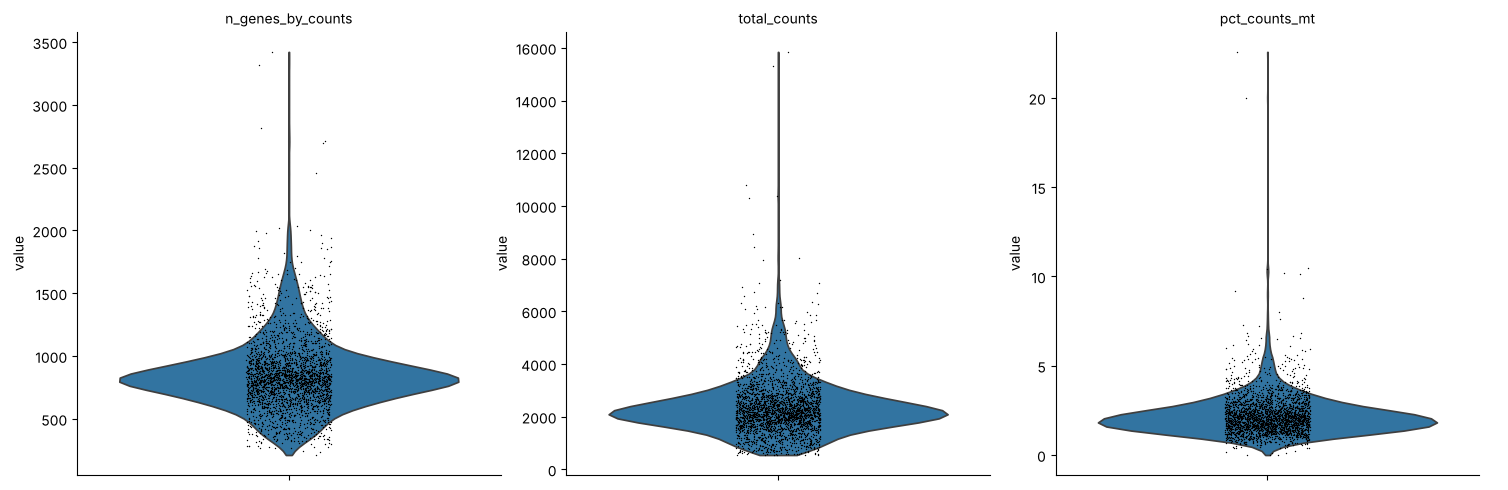

In [11]:
sc.pl.violin(adata, ["n_genes_by_counts", "total_counts", "pct_counts_mt"], multi_panel=True)

In [12]:
sc.pp.filter_cells(adata, min_genes=200)
sc.pp.filter_genes(adata, min_cells=3)

In [13]:
adata = adata[(adata.obs.n_genes_by_counts < 2500) & (adata.obs.pct_counts_mt < 5)].copy()

In [14]:
adata.layers["counts"] = adata.X.copy()

In [15]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: None (.X), 'counts'

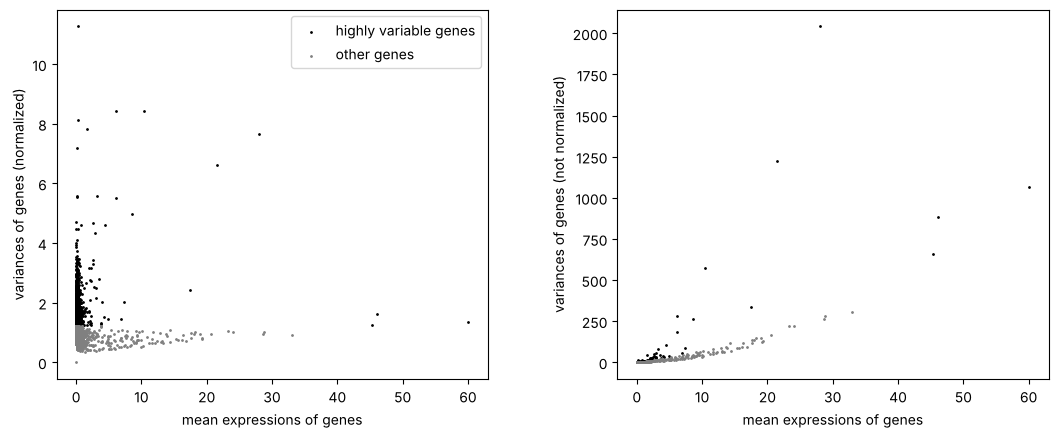

In [16]:
sc.pp.highly_variable_genes(adata, layer="counts", flavor="seurat_v3", n_top_genes=2000)
sc.pl.highly_variable_genes(adata)

In [17]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg'
    layers: None (.X), 'counts'

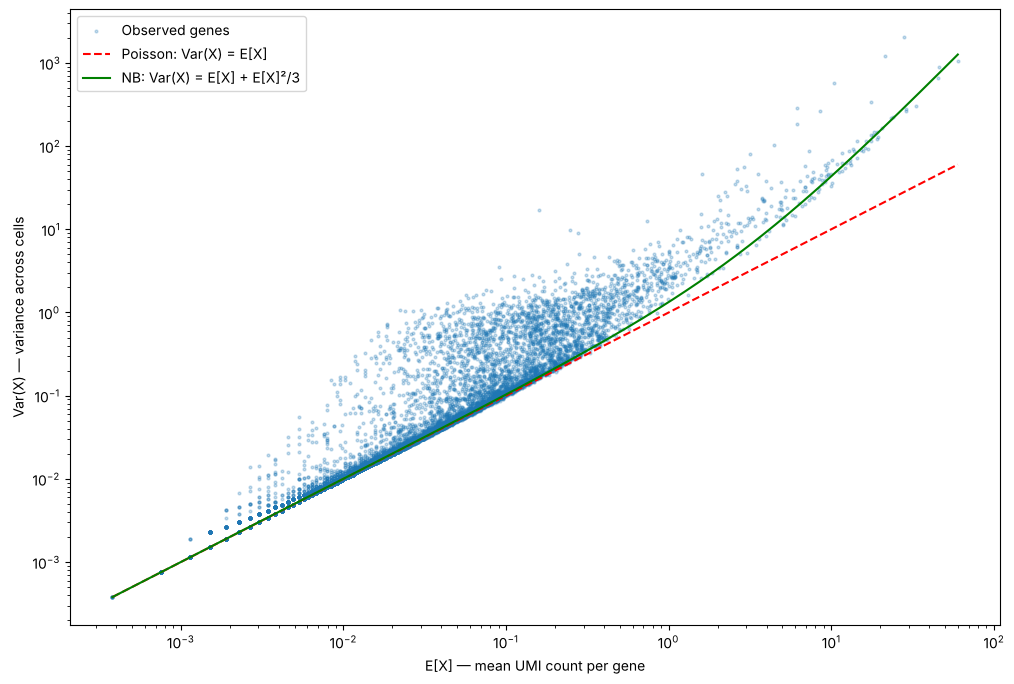

In [18]:
plt.figure(figsize=(12, 8))

mean = adata.var["means"].to_numpy()
var = adata.var["variances"].to_numpy()
valid = (mean > 0) & (var > 0)

theta = 3

x = np.geomspace(mean[valid].min(), mean[valid].max(), 200)

plt.scatter(mean[valid], var[valid], s=4, alpha=0.25, label="Observed genes")

plt.plot(x, x, "r--", label="Poisson: Var(X) = E[X]")
plt.plot(x, x + x**2/theta, "g-", label=f"NB: Var(X) = E[X] + E[X]²/{theta}")

plt.xscale("log")
plt.yscale("log")
plt.xlabel("E[X] — mean UMI count per gene")
plt.ylabel("Var(X) — variance across cells")
plt.legend()
plt.show()

In [19]:
sc.pp.normalize_total(adata, target_sum=1e4) # учитываем разный размер библиотеки. Нормализуем на глубину секвенирования
sc.pp.log1p(adata) # уменьшаем влияние сильно экспрессируемых генов

In [20]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p'
    layers: None (.X), 'counts'

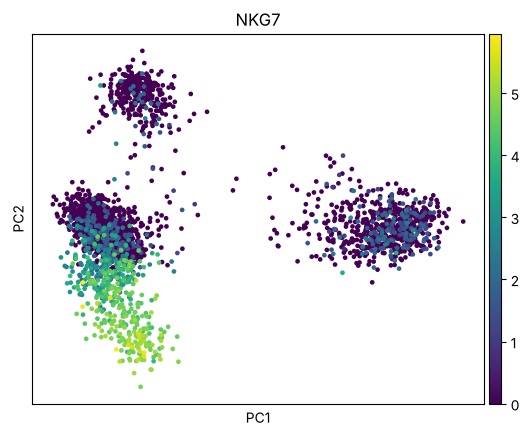

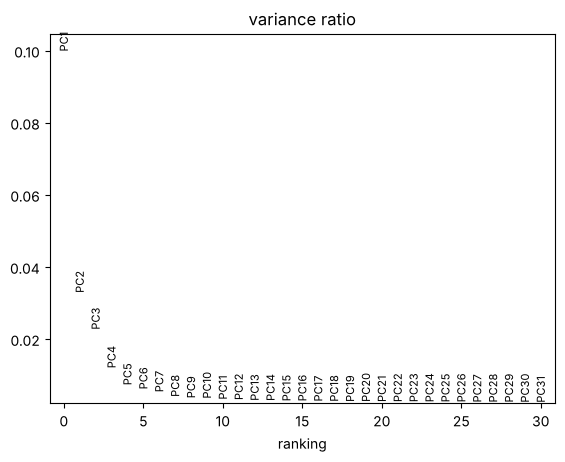

In [21]:
sc.tl.pca(adata, mask_var="highly_variable")
sc.pl.pca(adata, color="NKG7")
sc.pl.pca_variance_ratio(adata)

In [22]:
adata

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'

## Подумайте 

* Посмотрите что сейчас находится в слоях anndata. Что из себя представляют новые слои?
* По каким генам можно ещё делать QC?   
* Как лучше делать QC: по поиску генов по названиям в матрице или с помощью gtf/gff файла?
* Сколько есть генов на митохондриальной хросоме? Все ли они начинаются с mt?
* У человека митохондриальные гены начинаются с MT, у мыши с mt. Как начинаются митохондриальные гены у других организмов: у коров, собак, приматов?

In [23]:
# что сейчас лежит в adata после нормализации и PCA
print(adata)
print("слои:", list(adata.layers.keys()))
genes_show = ["MALAT1", "LYZ", "CD3D", "NKG7", "MS4A1"]
print("X (log1p после нормализации), 3 клетки × 5 генов:")
print(adata[:3, genes_show].X.toarray().round(2))
print("layers['counts'] (сырые UMI), те же клетки и гены:")
print(adata[:3, genes_show].layers["counts"].toarray())

AnnData object with n_obs × n_vars = 2638 × 13714
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'n_genes'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'hvg', 'log1p', 'pca'
    obsm: 'X_pca'
    varm: 'PCs'
    layers: None (.X), 'counts'
слои: [None, 'counts']
X (log1p после нормализации), 3 клетки × 5 генов:
[[5.32 1.64 2.86 0.   0.  ]
 [5.67 1.96 0.   1.11 2.58]
 [6.3  2.   3.49 0.   0.  ]]
layers['counts'] (сырые UMI), те же клетки и гены:
[[ 49.   1.   4.   0.   0.]
 [142.   3.   0.   1.   6.]
 [171.   2.  10.   0.   0.]]


In [24]:
# митохондриальные гены и гены, которые просто начинаются на "MT"
all_genes = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/").var_names
mt_dash = all_genes[all_genes.str.startswith("MT-")]
mt_nodash = all_genes[all_genes.str.startswith("MT") & ~all_genes.str.startswith("MT-")]
print("Генов с префиксом MT-:", len(mt_dash), list(mt_dash))
print("Генов на MT без дефиса (это НЕ митохондриальные):", len(mt_nodash))
print(list(mt_nodash[:15]))

Генов с префиксом MT-: 13 ['MT-ND1', 'MT-ND2', 'MT-CO1', 'MT-CO2', 'MT-ATP8', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4L', 'MT-ND4', 'MT-ND5', 'MT-ND6', 'MT-CYB']
Генов на MT без дефиса (это НЕ митохондриальные): 92
['MTOR', 'MTOR-AS1', 'MTHFR', 'MTFR1L', 'MTF1', 'MTF2', 'MTMR11', 'MTX1', 'MTR', 'MT1HL1', 'MTRNR2L11', 'MTA3', 'MTIF2', 'MTHFD2', 'MTX2']


### Ответы

**1. Что в слоях?** Слой `counts` — копия сырых UMI, сохранённая до нормализации. В `adata.X` теперь `log1p` от нормализованных (CP10K) значений. Ещё появились `obsm['X_pca']` (координаты клеток), `varm['PCs']` (loadings генов) и колонки HVG в `var`.

**2. По каким генам ещё делать QC?**
- рибосомные (`RPS*`, `RPL*`) — их доля зависит от типа клетки и качества;
- гемоглобины (`HBA1`, `HBA2`, `HBB`) — примесь эритроцитов;
- `MALAT1` — ядерная РНК, её много у клеток, потерявших цитоплазму.

Отдельно ищут дублеты (`scrublet`).

**3. По названиям или по gtf/gff?** Лучше по `gtf`/`gff`: там есть хромосома (`MT`) и тип гена. Названия зависят от аннотации и организма, а по `gtf` гены берутся с митохондриальной хромосомы.

**4. Сколько генов на митохондриальной хромосоме?** У человека 37: 13 белок-кодирующих, 22 тРНК и 2 рРНК. В нашей матрице 13 генов `MT-` — только белок-кодирующие. Не все гены на `MT` митохондриальные: 92 гена без дефиса (`MTOR`, `MT1A`, `MT2A`) лежат в ядерном геноме.

**5. Как у других организмов?** Единого правила нет: у мыши `mt-`, у приматов часто `MT-`, у коровы и собаки гены часто без приставки (`ND1`, `COX1`, `CYTB`). Поэтому надёжнее брать гены с хромосомы `MT` из `gtf`.


**Во всех заданиях если не сказано иного используйте анализ с использованием филтрации по QC и PCA с использованием HVG**

## Задание 1
Сделайте QC по предложенным вами генам/группам генов и постройти графики для всех QC - и тех что мы сделали сами и тех что вы предложили. 

Для каждой группы генов/гена рассчитайте долю UMI от общего количества UMI клетки.

Постройте для всех QC-метрик (включая рассчитанные на занятии):

1. Violin plot.
2. Гистограмму распределения:
   - X — значение QC-метрики;
   - Y — количество клеток.
3. Scatter plot зависимости количества обнаруженных генов от общего количества UMI.

**Вопросы:** Какие клетки выглядят подозрительными? Какие метрики могут свидетельствовать о низком качестве клетки? Почему высокая доля определённой группы генов не всегда означает плохое качество?


In [25]:
# Задание 1. QC по группам генов на НЕфильтрованных данных
import pandas as pd
from scipy.stats import spearmanr
adata_qc = sc.read_10x_mtx("data/filtered_gene_bc_matrices/hg19/")
v = adata_qc.var_names

hb_genes = ["HBA1", "HBA2", "HBB", "HBD", "HBG1", "HBG2", "HBE1", "HBZ", "HBM", "HBQ1"]

adata_qc.var["mt"] = v.str.startswith("MT-")                       # митохондриальные
adata_qc.var["ribo"] = v.str.match(r"^RP[SL]\d+[AXY]?\d*$") | v.isin(["RPLP0", "RPLP1", "RPLP2", "RPSA"])  # рибосомные белки
adata_qc.var["hb"] = v.isin(hb_genes)                              # гемоглобины (эритроциты)
adata_qc.var["malat1"] = v == "MALAT1"                             # ядерная lncRNA

for g in ["mt", "ribo", "hb", "malat1"]:
    print(g, adata_qc.var[g].sum())

sc.pp.calculate_qc_metrics(adata_qc, qc_vars=["mt", "ribo", "hb", "malat1"],
                           percent_top=None, log1p=False, inplace=True)

# дублеты (scrublet) — тоже метрика качества из лекции
sc.pp.scrublet(adata_qc, random_state=0)

qc_cols = ["n_genes_by_counts", "total_counts", "pct_counts_mt",
           "pct_counts_ribo", "pct_counts_hb", "pct_counts_malat1", "doublet_score"]
adata_qc.obs[qc_cols].describe().round(2)

mt 13
ribo 79
hb 10
malat1 1


,n_genes_by_counts,total_counts,pct_counts_mt,pct_counts_ribo,pct_counts_hb,pct_counts_malat1,doublet_score
count,2700.00,2700.00,2700.00,2700.00,2700.00,2700.00,2700.00
mean,846.99,2366.90,2.22,34.74,0.00,2.81,0.06
std,282.10,1094.26,1.17,10.19,0.03,1.80,0.05
min,212.00,548.00,0.00,1.06,0.00,0.00,0.01
25%,690.00,1757.75,1.54,26.19,0.00,1.56,0.03
50%,817.00,2197.00,2.03,36.52,0.00,2.59,0.04
75%,953.25,2763.00,2.64,43.13,0.00,3.64,0.07
max,3422.00,15844.00,22.57,59.11,1.36,17.51,0.51


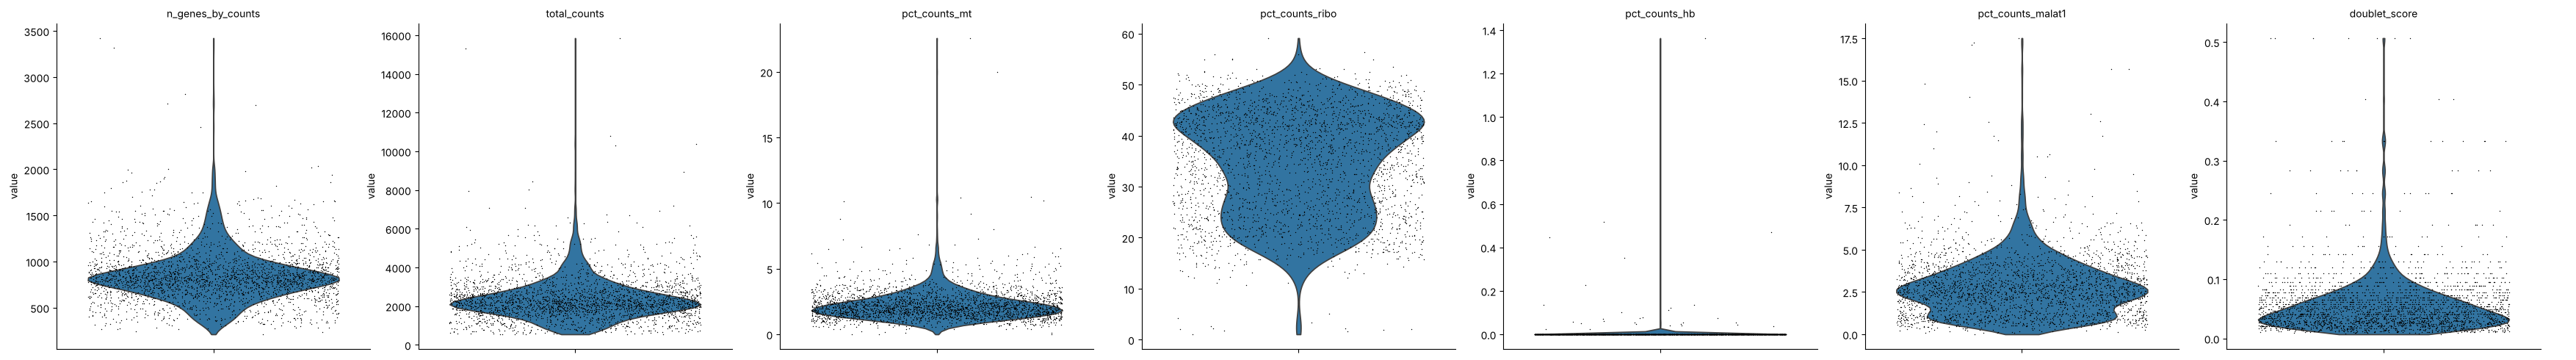

In [26]:
# 1. Violin plot
sc.pl.violin(adata_qc, qc_cols, multi_panel=True, jitter=0.4)

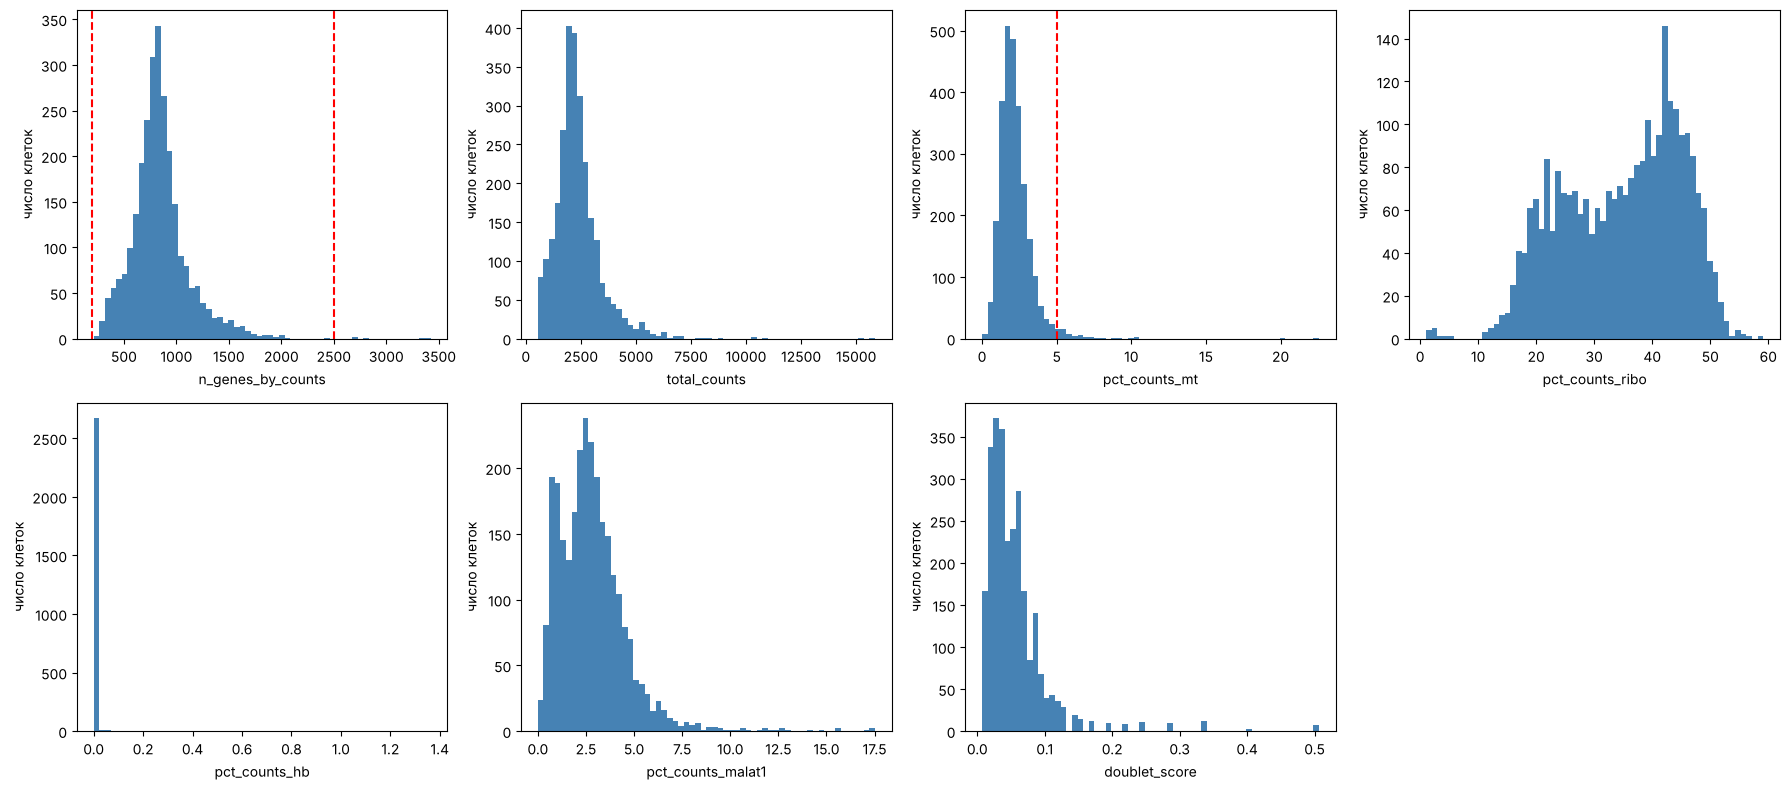

In [27]:
# 2. Гистограммы: X — значение метрики, Y — число клеток
thresholds = {"n_genes_by_counts": [200, 2500], "pct_counts_mt": [5]}
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), qc_cols):
    ax.hist(adata_qc.obs[col], bins=60, color="steelblue")
    for t in thresholds.get(col, []):
        ax.axvline(t, color="red", ls="--")
    ax.set_xlabel(col)
    ax.set_ylabel("число клеток")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

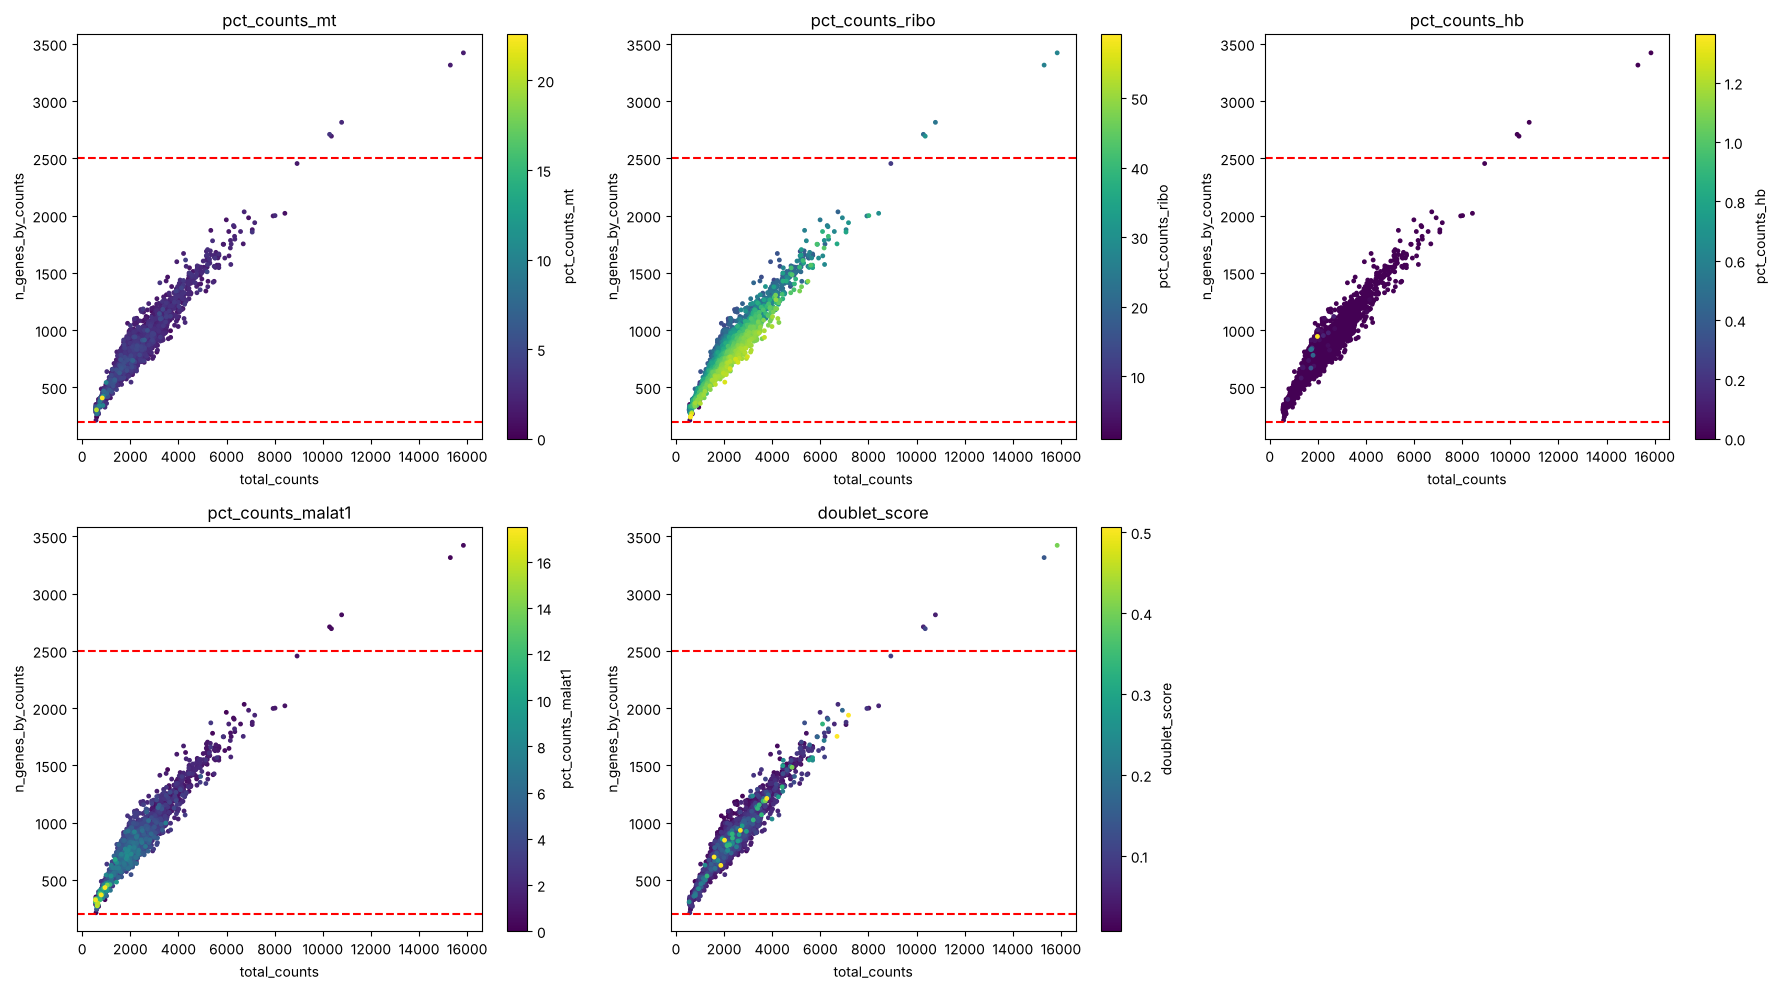

In [28]:
# 3. Scatter: число генов от общего числа UMI, окраска по разным QC
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for ax, col in zip(axes.ravel(), ["pct_counts_mt", "pct_counts_ribo", "pct_counts_hb",
                                  "pct_counts_malat1", "doublet_score"]):
    o = adata_qc.obs.sort_values(col)
    s = ax.scatter(o["total_counts"], o["n_genes_by_counts"], c=o[col], s=6, cmap="viridis")
    plt.colorbar(s, ax=ax, label=col)
    ax.axhline(200, color="red", ls="--"); ax.axhline(2500, color="red", ls="--")
    ax.set_xlabel("total_counts"); ax.set_ylabel("n_genes_by_counts"); ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.show()

In [29]:
# сколько клеток подозрительны по каждому критерию
o = adata_qc.obs
crit = {
    "мало генов (<200)": o.n_genes_by_counts < 200,
    "много генов (>2500)": o.n_genes_by_counts > 2500,
    "pct_mt > 5%": o.pct_counts_mt > 5,
    "pct_hb > 1%": o.pct_counts_hb > 1,
    "predicted_doublet": o.predicted_doublet,
}
for k, m in crit.items():
    print(f"{k}: {m.sum()} клеток")
print("\nКлетки с pct_mt > 5% против остальных (медианы):")
print(o.groupby(o.pct_counts_mt > 5)[["n_genes_by_counts", "total_counts", "pct_counts_ribo", "pct_counts_malat1"]].median().round(1))
print("\nМного генов (>2500) против остальных (медианы):")
print(o.groupby(o.n_genes_by_counts > 2500)[["total_counts", "doublet_score"]].median().round(2))

мало генов (<200): 0 клеток
много генов (>2500): 5 клеток
pct_mt > 5%: 57 клеток
pct_hb > 1%: 1 клеток
predicted_doublet: 32 клеток

Клетки с pct_mt > 5% против остальных (медианы):
               n_genes_by_counts  total_counts  pct_counts_ribo  \
pct_counts_mt                                                     
False                      821.0        2216.0        36.700001   
True                       462.0        1025.0        30.500000   

               pct_counts_malat1  
pct_counts_mt                     
False                        2.6  
True                         4.1  

Много генов (>2500) против остальных (медианы):
                   total_counts  doublet_score
n_genes_by_counts                             
False                    2196.0           0.04
True                    10783.0           0.11


In [30]:
# переносим новые QC-метрики в основной adata (там клетки после фильтрации)
for col in ["pct_counts_ribo", "pct_counts_hb", "pct_counts_malat1", "doublet_score"]:
    adata.obs[col] = adata_qc.obs.loc[adata.obs_names, col].values
adata.obs[["pct_counts_ribo", "pct_counts_hb", "doublet_score"]].describe().round(2)

,pct_counts_ribo,pct_counts_hb,doublet_score
count,2638.00,2638.00,2638.00
mean,34.84,0.00,0.06
std,10.20,0.03,0.05
min,1.06,0.00,0.01
25%,26.21,0.00,0.03
50%,36.67,0.00,0.04
75%,43.22,0.00,0.07
max,59.11,1.36,0.51


### Выводы и ответы

Посчитала доли UMI для групп: `mt` (13 генов), `ribo` (79), `hb` (10), `malat1`, плюс `doublet_score` из `scrublet`.

**1. Какие клетки подозрительные?**
- 57 клеток с `pct_counts_mt` > 5% (до 22%). У них почти вдвое меньше генов (462 против 821) и UMI (1025 против 2216). Это похоже на повреждённые клетки.
- 5 клеток с > 2500 генами: у них ~10 800 UMI (в 5 раз больше медианы) и выше `doublet_score`. Скорее всего дублеты. `scrublet` отметил ещё 32 клетки.
- Клеток с < 200 генами нет: пустые капли уже убрал Cell Ranger.
- Гемоглобин почти у всех 0 (максимум 1.4%), эритроцитов почти нет.

**2. Какие метрики говорят о плохом качестве?** Высокая `pct_counts_mt`, мало генов и UMI (особенно вместе), высокая доля `MALAT1`. Слишком много генов и UMI или высокий `doublet_score` — признак дублета. На scatter хорошие клетки лежат на одной диагонали, плохие уходят в левый нижний угол или в правый верхний.

**3. Почему высокая доля группы генов не всегда плохо?** Она может быть биологической. У доли рибосомных генов на гистограмме и scatter видны две группы: у лимфоцитов их больше, у моноцитов меньше. `MT-` высокий у метаболически активных клеток, `HB` — у эритроцитов, которые тоже есть в крови.


## Задание 2. Сравнение методов отбора HVG

Мы использовали `seurat_v3`. Повторите отбор HVG методом `seurat`, а также попробуйте использовать `sc.experimental.pp.highly_variable_genes`. 

Постройте PCA на генах, отобранных каждым методом. Для обоих PCA используйте одинаковую нормализованную и логарифмированную матрицу экспрессии.

Окрасьте клетки по экспрессии известных маркеров иммунных популяций:

| Популяция | Ген |
|---|---|
| T-клетки | `CD3D` |
| B-клетки | `MS4A1` |
| NK-клетки | `NKG7` |
| Моноциты | `LST1` |

Эти гены используются как ориентиры, а не как окончательные аннотации клеточных типов.

**Вопросы:** Насколько отличаются расположения клеток? Сохраняются ли группы клеток с характерной экспрессией маркеров? Сколько генов одновременно попало в оба набора HVG?


In [31]:
# Задание 2. Три способа отбора HVG; PCA везде на одной и той же log1p-матрице adata.X
markers = ["CD3D", "MS4A1", "NKG7", "LST1"]
hvg_sets = {}

# 1) seurat_v3 — уже посчитан на занятии (на сырых counts)
hvg_sets["seurat_v3"] = set(adata.var_names[adata.var["highly_variable"]])

# 2) seurat — работает с лог-нормализованными данными
tmp = adata.copy()
sc.pp.highly_variable_genes(tmp, flavor="seurat", n_top_genes=2000)
hvg_sets["seurat"] = set(tmp.var_names[tmp.var["highly_variable"]])

# 3) experimental: остатки Пирсона (pearson residuals), на сырых counts
tmp = adata.copy()
tmp.X = tmp.layers["counts"].copy()
sc.experimental.pp.highly_variable_genes(tmp, flavor="pearson_residuals", n_top_genes=2000)
hvg_sets["pearson_residuals"] = set(tmp.var_names[tmp.var["highly_variable"]])

for name, genes in hvg_sets.items():
    print(name, len(genes))

seurat_v3 2000
seurat 2000
pearson_residuals 2000


seurat_v3


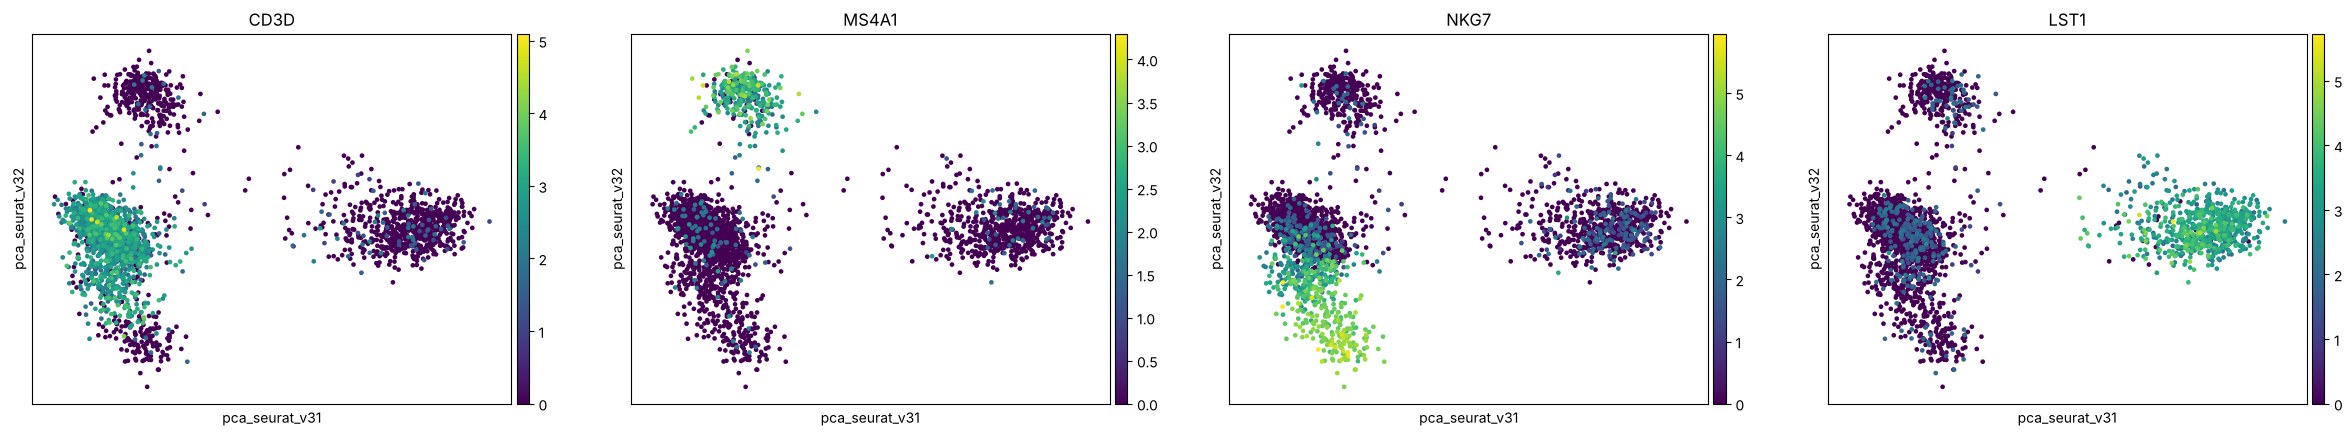

seurat


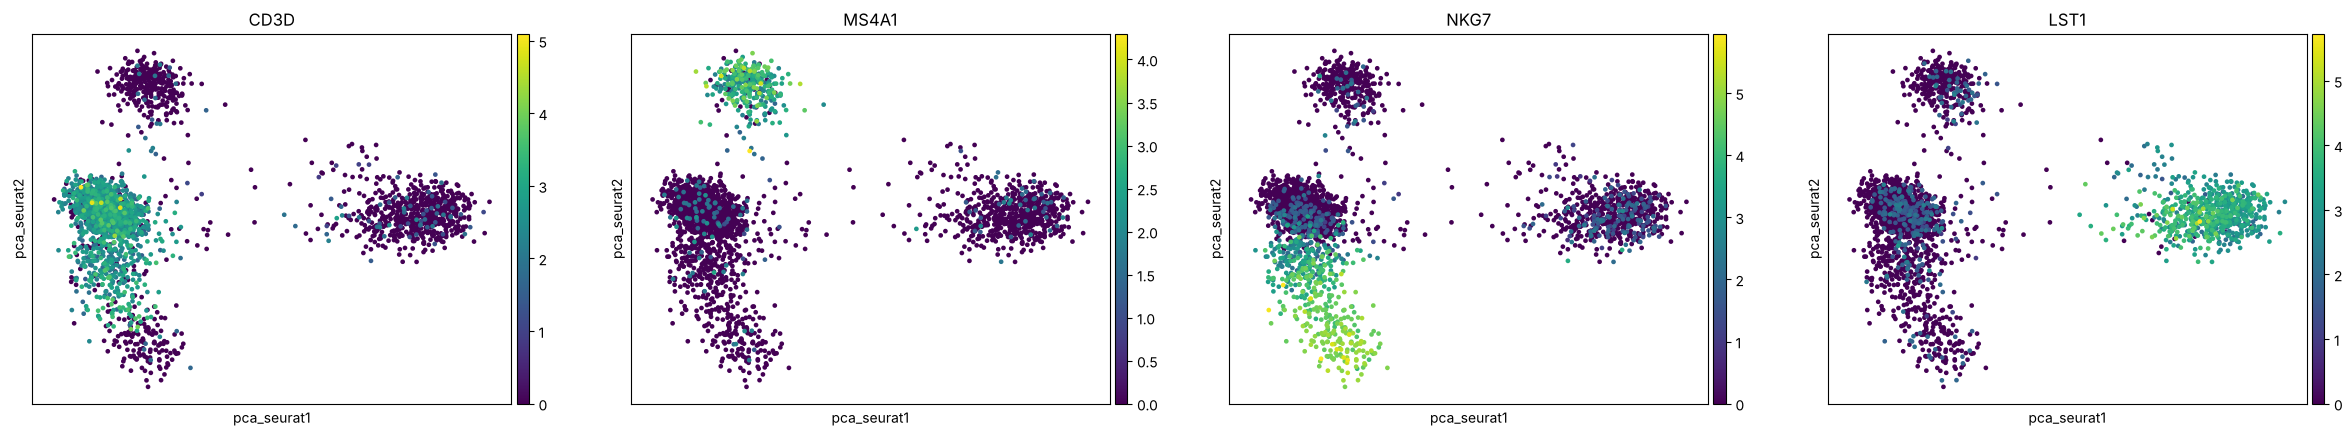

pearson_residuals


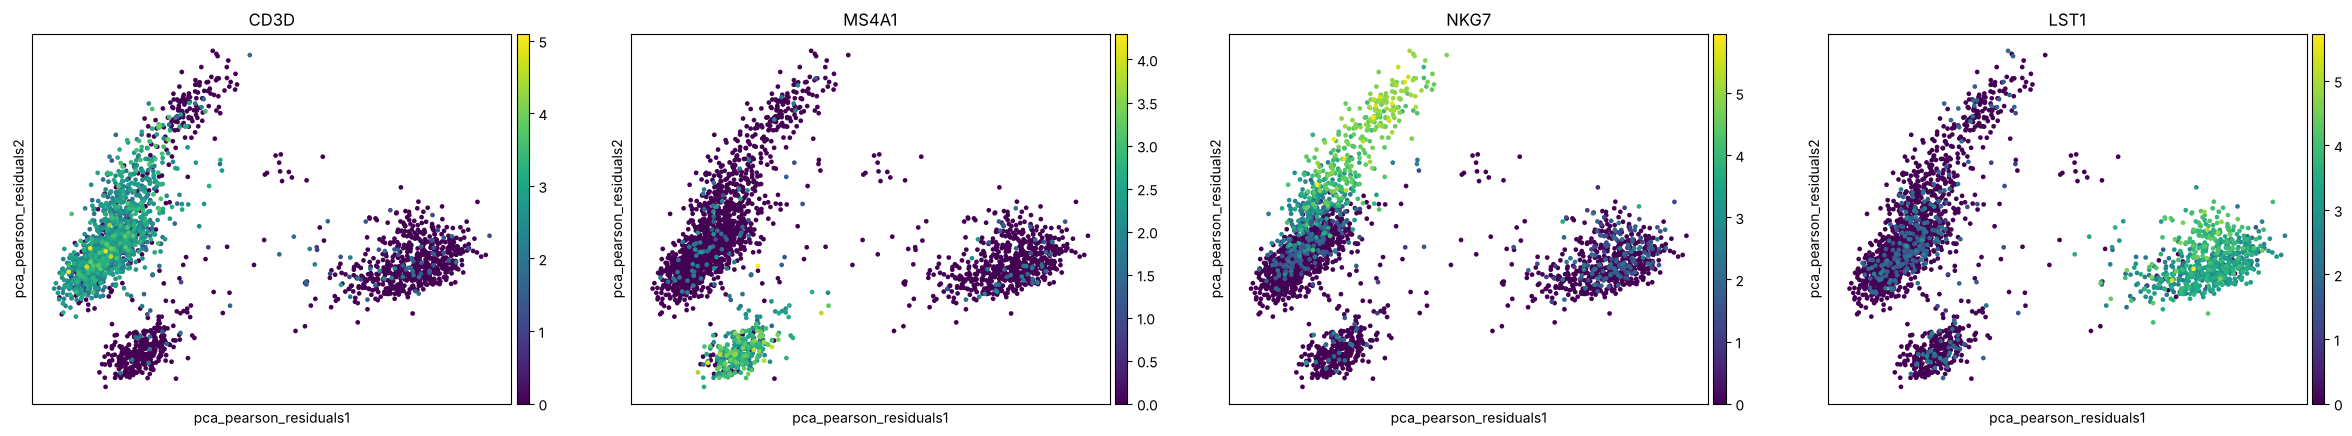

In [32]:
# PCA по каждому набору HVG
for name, genes in hvg_sets.items():
    tmp = adata.copy()
    tmp.var["hvg_tmp"] = tmp.var_names.isin(list(genes))
    sc.tl.pca(tmp, mask_var="hvg_tmp")
    adata.obsm[f"X_pca_{name}"] = tmp.obsm["X_pca"]
    adata.uns[f"var_ratio_{name}"] = tmp.uns["pca"]["variance_ratio"]
    print(name)
    sc.pl.embedding(adata, basis=f"pca_{name}", color=markers, ncols=4)

In [33]:
# пересечения наборов HVG
a, b, c = hvg_sets["seurat_v3"], hvg_sets["seurat"], hvg_sets["pearson_residuals"]
print("seurat_v3 ∩ seurat:", len(a & b))
print("seurat_v3 ∩ pearson:", len(a & c))
print("seurat ∩ pearson:", len(b & c))
print("во всех трёх:", len(a & b & c))

# насколько похожи сами координаты PC1/PC2 (знак компоненты произволен, поэтому берём |r|)
rows = []
for n1, n2 in [("seurat_v3", "seurat"), ("seurat_v3", "pearson_residuals"), ("seurat", "pearson_residuals")]:
    for k in [0, 1]:
        r = np.corrcoef(adata.obsm[f"X_pca_{n1}"][:, k], adata.obsm[f"X_pca_{n2}"][:, k])[0, 1]
        rows.append([f"{n1} vs {n2}", f"PC{k+1}", round(abs(r), 3)])
pd.DataFrame(rows, columns=["пара", "компонента", "|r|"])

seurat_v3 ∩ seurat: 1505
seurat_v3 ∩ pearson: 1402
seurat ∩ pearson: 1291
во всех трёх: 1145


,пара,компонента,|r|
0,seurat_v3 vs seurat,PC1,0.997
1,seurat_v3 vs seurat,PC2,0.991
2,seurat_v3 vs pearson_residuals,PC1,0.990
3,seurat_v3 vs pearson_residuals,PC2,0.928
4,seurat vs pearson_residuals,PC1,0.990
5,seurat vs pearson_residuals,PC2,0.944


### Выводы и ответы

**1. Насколько отличаются расположения клеток?** Почти не отличаются: корреляция PC1 между методами |r| ≥ 0.99, PC2 — 0.93–0.99. У pearson residuals PC2 перевёрнута (B-клетки внизу, NK вверху), но знак компоненты произвольный, так что это не настоящее отличие.

**2. Сохраняются ли группы?** Да, во всех трёх вариантах видны T-клетки (`CD3D`), B-клетки (`MS4A1`), NK (`NKG7`) и моноциты (`LST1`). PC1 везде отделяет моноциты от лимфоцитов.

**3. Сколько генов совпало?** `seurat_v3` и `seurat` — 1505 из 2000, `seurat_v3` и pearson — 1402, `seurat` и pearson — 1291, во всех трёх — 1145. Списки отличаются, потому что методы по-разному учитывают связь дисперсии со средним. Но маркеры типов попадают во все наборы, поэтому структура PCA одна.


## Задание 3. PCA без отбора HVG

Повторите PCA, используя все гены, прошедшие QC, без ограничения набором HVG.

Сравните результат с PCA, построенным по 2000 HVG.

Используйте те же маркеры и одинаковые настройки нормализации и масштабирования данных.

**Вопросы:** Как изменилась структура клеток? Какие компоненты объясняют больше дисперсии? Почему использование всех доступных генов не обязательно делает PCA информативнее?


генов в PCA: 13714 против HVG: 2000
PCA по 2000 HVG


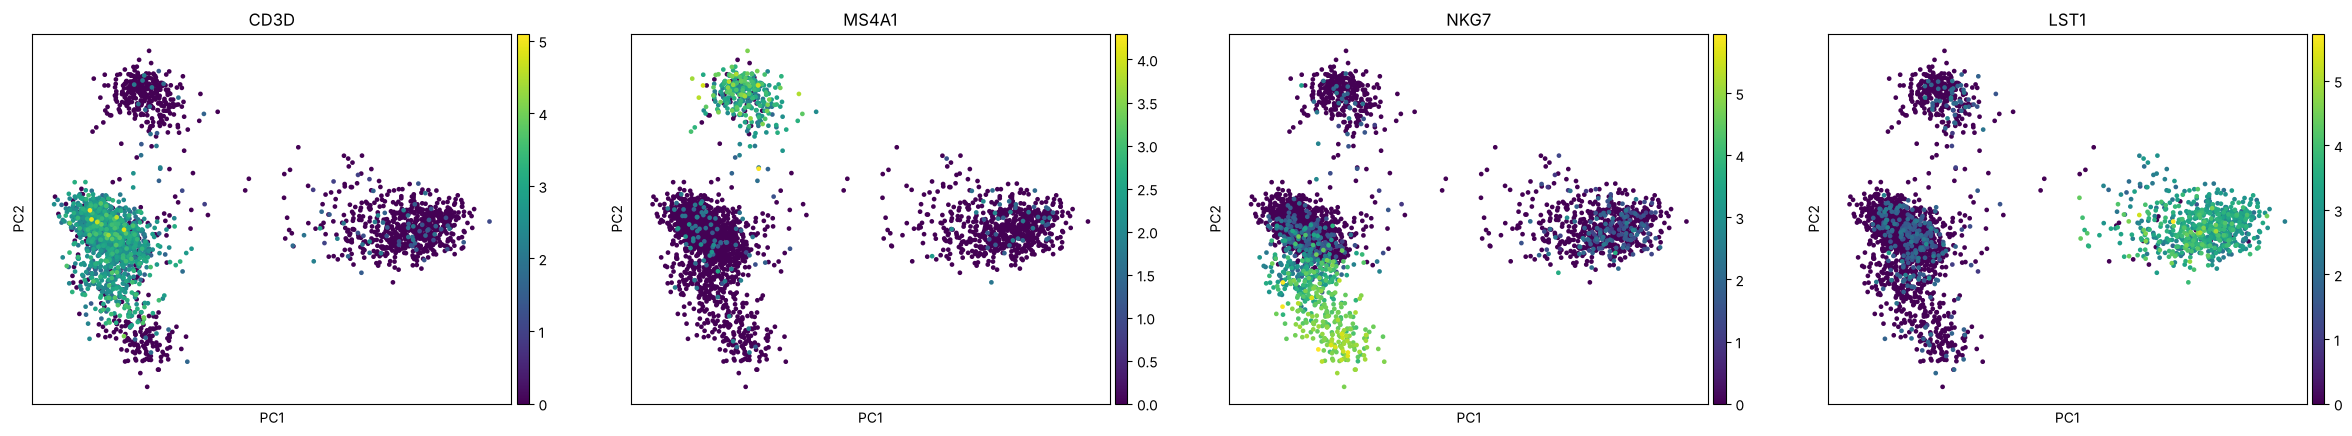

PCA по всем генам


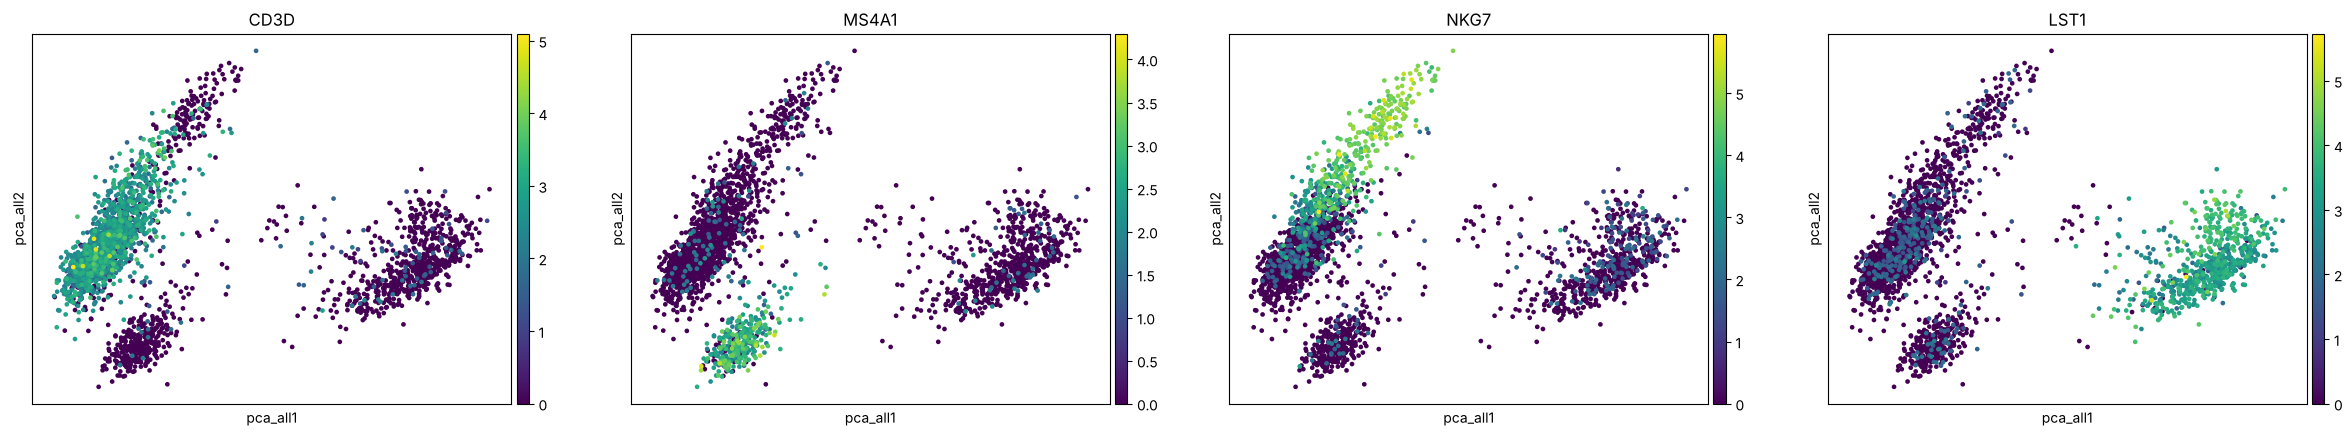

In [34]:
# Задание 3. PCA на всех генах, прошедших QC (mask_var=None — иначе scanpy сам возьмёт HVG)
tmp = adata.copy()
sc.tl.pca(tmp, mask_var=None)
adata.obsm["X_pca_all"] = tmp.obsm["X_pca"]
adata.uns["var_ratio_all"] = tmp.uns["pca"]["variance_ratio"]
print("генов в PCA:", tmp.n_vars, "против HVG:", int(adata.var["highly_variable"].sum()))

print("PCA по 2000 HVG")
sc.pl.pca(adata, color=markers, ncols=4)
print("PCA по всем генам")
sc.pl.embedding(adata, basis="pca_all", color=markers, ncols=4)

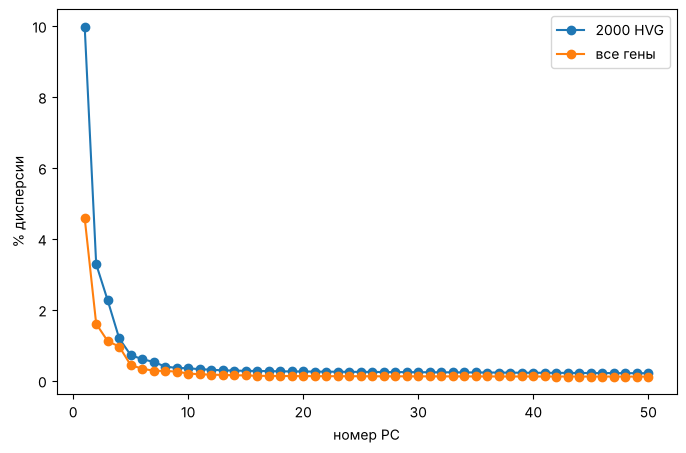

,PC1,PC2,PC3,PC4,PC5,"сумма PC1-10, %"
"2000 HVG, %",9.98,3.28,2.26,1.19,0.72,19.700001
"все гены, %",4.58,1.60,1.11,0.96,0.44,10.000000


In [35]:
# сколько дисперсии объясняют компоненты
vr_hvg = adata.uns["pca"]["variance_ratio"]
vr_all = adata.uns["var_ratio_all"]
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, 51), vr_hvg * 100, "o-", label="2000 HVG")
plt.plot(np.arange(1, 51), vr_all * 100, "o-", label="все гены")
plt.xlabel("номер PC"); plt.ylabel("% дисперсии"); plt.legend(); plt.show()

pd.DataFrame({
    "2000 HVG, %": (vr_hvg[:5] * 100).round(2),
    "все гены, %": (vr_all[:5] * 100).round(2),
}, index=[f"PC{i}" for i in range(1, 6)]).T.assign(
    **{"сумма PC1-10, %": [round(vr_hvg[:10].sum() * 100, 1), round(vr_all[:10].sum() * 100, 1)]})

### Выводы и ответы

**1. Как изменилась структура?** Группы те же, но лимфоциты вытянуты по диагонали, и T- и NK-клетки сливаются сильнее, чем на HVG.

**2. Какие компоненты объясняют больше дисперсии?** На HVG больше: PC1 — 10.0% против 4.6% на всех генах, PC1–10 — 19.7% против 10.0%.

**3. Почему все гены не делают PCA лучше?** Большинство из 13 714 генов почти не меняются между клетками, их разброс — шум (много нулей). Этот шум добавляет дисперсию, не связанную с типами клеток, и размывает компоненты. Плюс проклятие размерности: чем больше признаков, тем хуже видны соседи.


## Задание 4. HVG и уровень экспрессии

Получите два списка:

- Гены, отобранные как HVG.
- Гены, не попавшие в HVG.

В каждом списке найдите 50 генов с наибольшим средним количеством UMI на клетку по исходным counts.

Сравните средний уровень экспрессии, дисперсию и известные функции этих генов.

**Вопросы:** Обязательно ли HVG являются наиболее экспрессируемыми генами? Почему ген может иметь очень высокую экспрессию, но не попасть в HVG? Какие группы генов встречаются среди наиболее экспрессируемых?


In [36]:
# Задание 4. HVG и уровень экспрессии (средние по исходным counts)
counts = adata.layers["counts"]
mean_c = np.asarray(counts.mean(axis=0)).ravel()
var_c = np.asarray(counts.multiply(counts).mean(axis=0)).ravel() - mean_c**2

def group(g):
    if g.startswith("MT-"): return "митохондриальный"
    if g.startswith(("RPL", "RPS")): return "рибосомный белок"
    if g in ["EEF1A1", "TPT1", "EIF3H", "PTMA", "UBB", "OAZ1"]: return "housekeeping / трансляция"
    if g in ["TMSB4X", "TMSB10", "ACTB", "VIM", "ARPC1B", "COTL1"]: return "цитоскелет"
    if g in ["FTL", "FTH1"]: return "ферритин (железо)"
    if g == "MALAT1": return "ядерная lncRNA"
    if g == "B2M": return "MHC I"
    if g.startswith("HLA-D") or g == "CD74": return "MHC II (B-кл., моноциты)"
    if g in ["LYZ", "S100A8", "S100A9", "CST3", "TYROBP", "FCER1G", "FCN1", "AIF1", "LST1", "CTSS", "PSAP", "TYMP", "SAT1", "LGALS1"]: return "моноциты"
    if g in ["GNLY", "NKG7", "GZMB", "GZMA", "PRF1", "CCL5", "CST7", "CTSW"]: return "цитотоксические (NK/CD8)"
    if g in ["LTB", "IL32", "IL7R", "CD3D", "CD2"]: return "T-клетки"
    return ""

df = pd.DataFrame({"mean_counts": mean_c, "var_counts": var_c,
                   "variances_norm": adata.var["variances_norm"].values,
                   "HVG": adata.var["highly_variable"].values}, index=adata.var_names)
df["группа"] = [group(g) for g in df.index]

top_hvg = df[df.HVG].sort_values("mean_counts", ascending=False).head(50)
top_non = df[~df.HVG].sort_values("mean_counts", ascending=False).head(50)

print("Сравнение двух топ-50 (медианы):")
pd.DataFrame({"HVG": top_hvg[["mean_counts", "var_counts", "variances_norm"]].median(),
              "не HVG": top_non[["mean_counts", "var_counts", "variances_norm"]].median()}).round(2)

Сравнение двух топ-50 (медианы):


,HVG,не HVG
mean_counts,2.63,12.93
var_counts,29.46,67.72
variances_norm,2.02,0.80


In [37]:
print("Топ-50 HVG по средней экспрессии")
top_hvg.round(2)

Топ-50 HVG по средней экспрессии


,mean_counts,var_counts,variances_norm,HVG,группа
MALAT1,60.040001,1066.569946,1.35,True,ядерная lncRNA
TMSB4X,46.139999,883.349976,1.64,True,цитоскелет
B2M,45.290001,659.150024,1.25,True,MHC I
FTL,28.000000,2041.890015,7.67,True,ферритин (железо)
FTH1,21.540001,1224.520020,6.64,True,ферритин (железо)
ACTB,17.459999,334.399994,2.42,True,цитоскелет
LYZ,10.410000,575.140015,8.43,True,моноциты
CD74,8.580000,261.790009,4.97,True,"MHC II (B-кл., моноциты)"
S100A4,7.340000,86.239998,2.02,True,
MT-CO2,6.890000,56.959999,1.45,True,митохондриальный


In [38]:
print("Топ-50 НЕ HVG по средней экспрессии")
top_non.round(2)

Топ-50 НЕ HVG по средней экспрессии


,mean_counts,var_counts,variances_norm,HVG,группа
RPL10,33.020000,307.450012,0.92,False,рибосомный белок
RPL13,28.770000,280.540009,1.01,False,рибосомный белок
RPL13A,28.639999,264.609985,0.96,False,рибосомный белок
RPS2,24.090000,222.750000,1.03,False,рибосомный белок
RPS6,23.290001,217.960007,1.06,False,рибосомный белок
RPS18,20.610001,166.669998,0.96,False,рибосомный белок
RPL11,19.290001,128.380005,0.81,False,рибосомный белок
RPL32,19.240000,122.029999,0.77,False,рибосомный белок
RPS3,19.010000,146.750000,0.94,False,рибосомный белок
RPL19,18.270000,149.699997,1.02,False,рибосомный белок


Группы генов в топ-50 HVG:
группа
моноциты                     14
другое                       13
цитоскелет                    5
MHC II (B-кл., моноциты)      5
housekeeping / трансляция     3
цитотоксические (NK/CD8)      3
ферритин (железо)             2
T-клетки                      2
ядерная lncRNA                1
MHC I                         1
митохондриальный              1
Name: count, dtype: int64

Группы генов в топ-50 не HVG:
группа
рибосомный белок             45
housekeeping / трансляция     3
митохондриальный              1
цитоскелет                    1
Name: count, dtype: int64


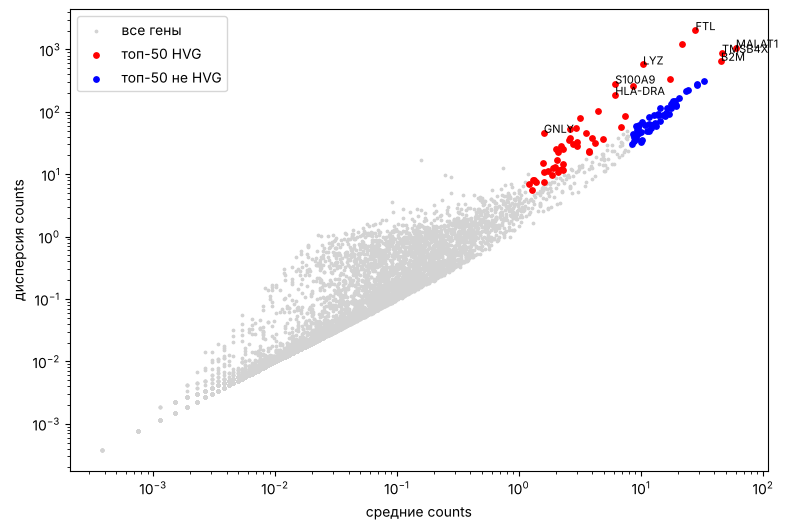

In [39]:
print("Группы генов в топ-50 HVG:"); print(top_hvg["группа"].replace("", "другое").value_counts())
print("\nГруппы генов в топ-50 не HVG:"); print(top_non["группа"].replace("", "другое").value_counts())

# среднее vs дисперсия, выделены оба топ-50
plt.figure(figsize=(9, 6))
plt.scatter(df.mean_counts, df.var_counts, s=3, c="lightgrey", label="все гены")
plt.scatter(top_hvg.mean_counts, top_hvg.var_counts, s=15, c="red", label="топ-50 HVG")
plt.scatter(top_non.mean_counts, top_non.var_counts, s=15, c="blue", label="топ-50 не HVG")
for g in ["MALAT1", "TMSB4X", "B2M", "LYZ", "S100A9", "HLA-DRA", "FTL", "GNLY"]:
    if g in df.index:
        plt.annotate(g, (df.loc[g, "mean_counts"], df.loc[g, "var_counts"]), fontsize=8)
plt.xscale("log"); plt.yscale("log"); plt.xlabel("средние counts"); plt.ylabel("дисперсия counts")
plt.legend(); plt.show()

### Выводы и ответы

**Сравнение.** У топ-50 не-HVG среднее выше (медиана 12.9 против 2.6) и даже сырая дисперсия выше (67.7 против 29.5). Но `variances_norm` (дисперсия относительно ожидаемой при таком среднем) ниже: 0.8 против 2.0.

**1. Обязательно ли HVG — самые экспрессируемые?** Нет. HVG — гены, у которых разброс больше ожидаемого для их уровня экспрессии.

**2. Почему ген с высокой экспрессией может не попасть в HVG?** Если он одинаково высоко экспрессирован во всех клетках. Для NB дисперсия растёт со средним (`σ² = μ + αμ²`), и у таких генов она ровно такая, какая ожидается.

**3. Какие группы среди самых экспрессируемых?**
- не HVG: 45 из 50 — рибосомные белки (`RPL*`, `RPS*`), плюс `EEF1A1`, `TPT1`, `PTMA`, `MT-CO1` — гены, нужные всем клеткам;
- HVG: маркеры типов — моноциты (`LYZ`, `S100A8`, `S100A9`, `CST3`), MHC II (`HLA-DRA`, `CD74`), NK/CD8 (`NKG7`, `GNLY`, `CCL5`), T-клетки (`LTB`, `IL32`). Есть и общие гены (`MALAT1`, `TMSB4X`, `B2M`, `FTL`), но они заметно меняются между типами.


## Задание 5. Влияние QC-метрик на PCA

Постройте несколько PCA plots для случаев:

1. Не используя фильтрацию и QC и не используя поиск HVG.
2. Не используя фильтрацию и QC, но используя поиск HVG.
3. Используя фильтрацию и QC, но не используя поиск HVG.
4. Используя фильтрацию и QC и используя поиск HVG.

Окрашивайте клетки по:

1. `total_counts` — общее число UMI клетки.
2. `n_genes_by_counts` — число обнаруженных генов.
3. `pct_counts_mt` — доля митохондриальных UMI.
4. Доле рибосомных UMI из задания 1.

Дополнительно постройте scatter plot:

- X — `total_counts`
- Y — `n_genes_by_counts`
- цвет — `pct_counts_mt`

Теперь повторите анализ не используя фильтрацию и QC но используя HVG

**Вопросы:** Связано ли положение клеток на PCA с количеством зарегистрированных UMI? Есть ли направления, вдоль которых меняется доля митохондриальных транскриптов? Можно ли по этим графикам заподозрить, что технические факторы влияют на главные компоненты?

1) без QC, без HVG — клеток: 2700


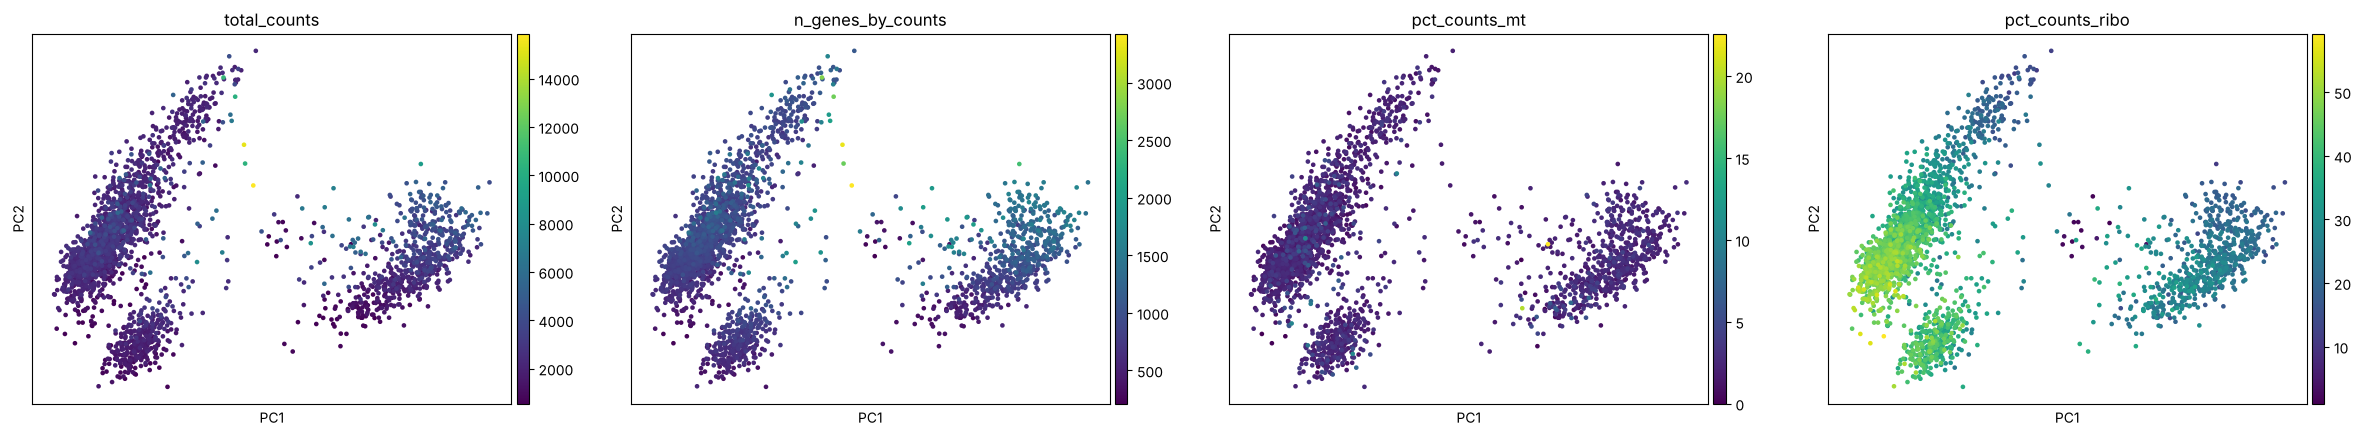

2) без QC, с HVG — клеток: 2700


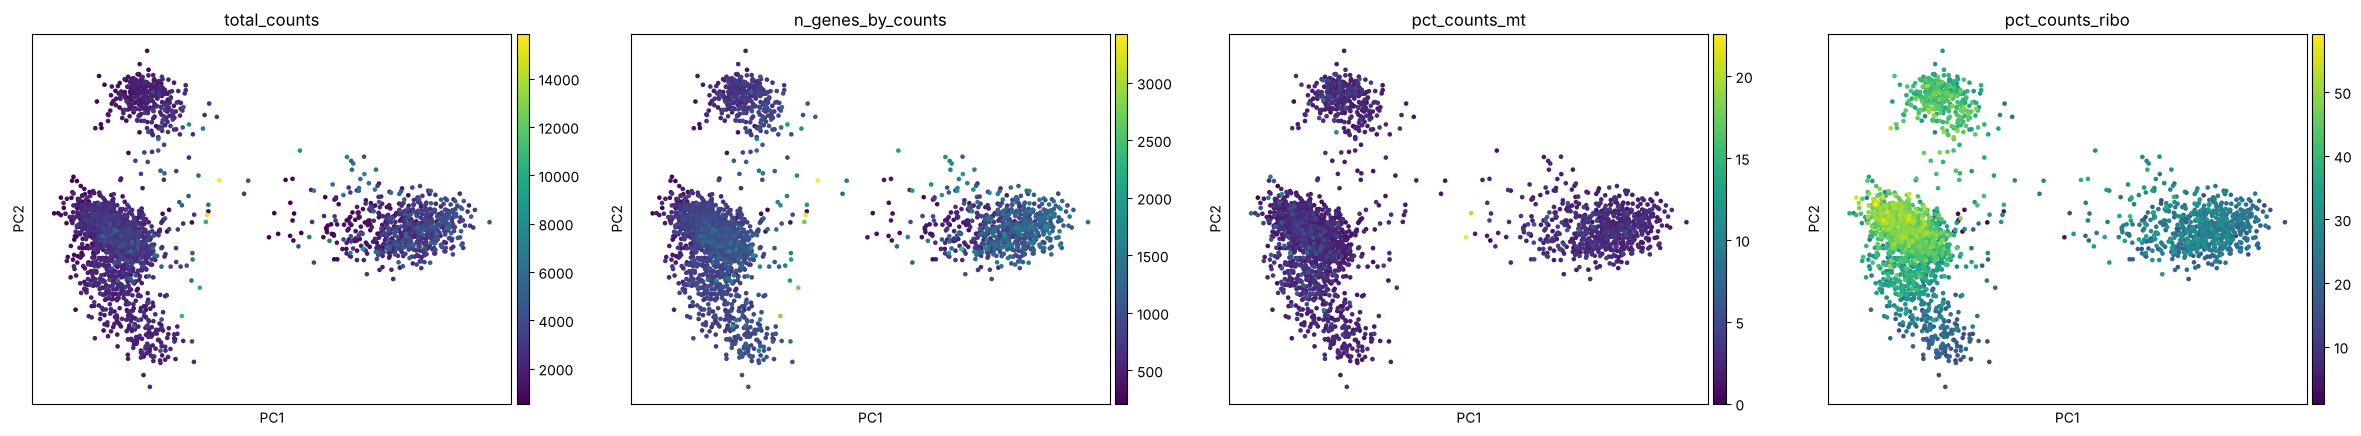

3) с QC, без HVG — клеток: 2638


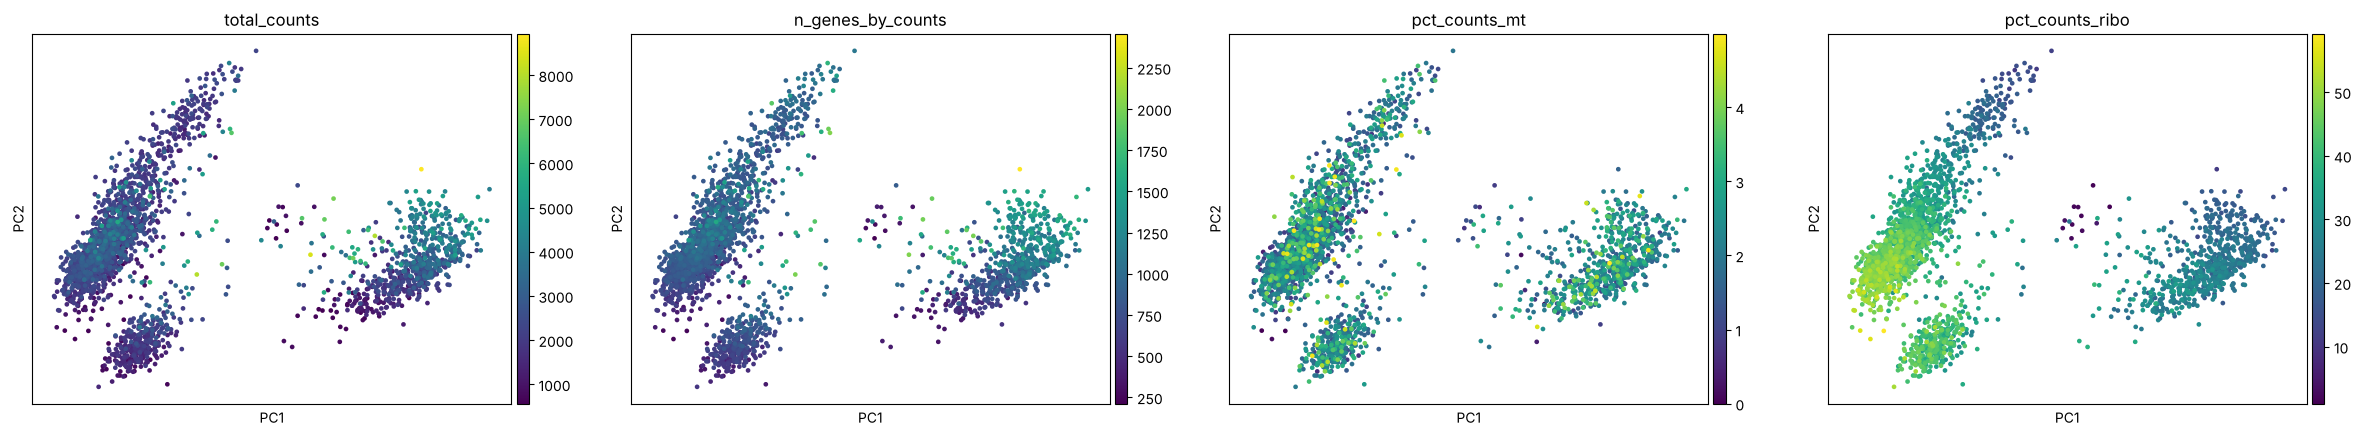

4) с QC, с HVG — клеток: 2638


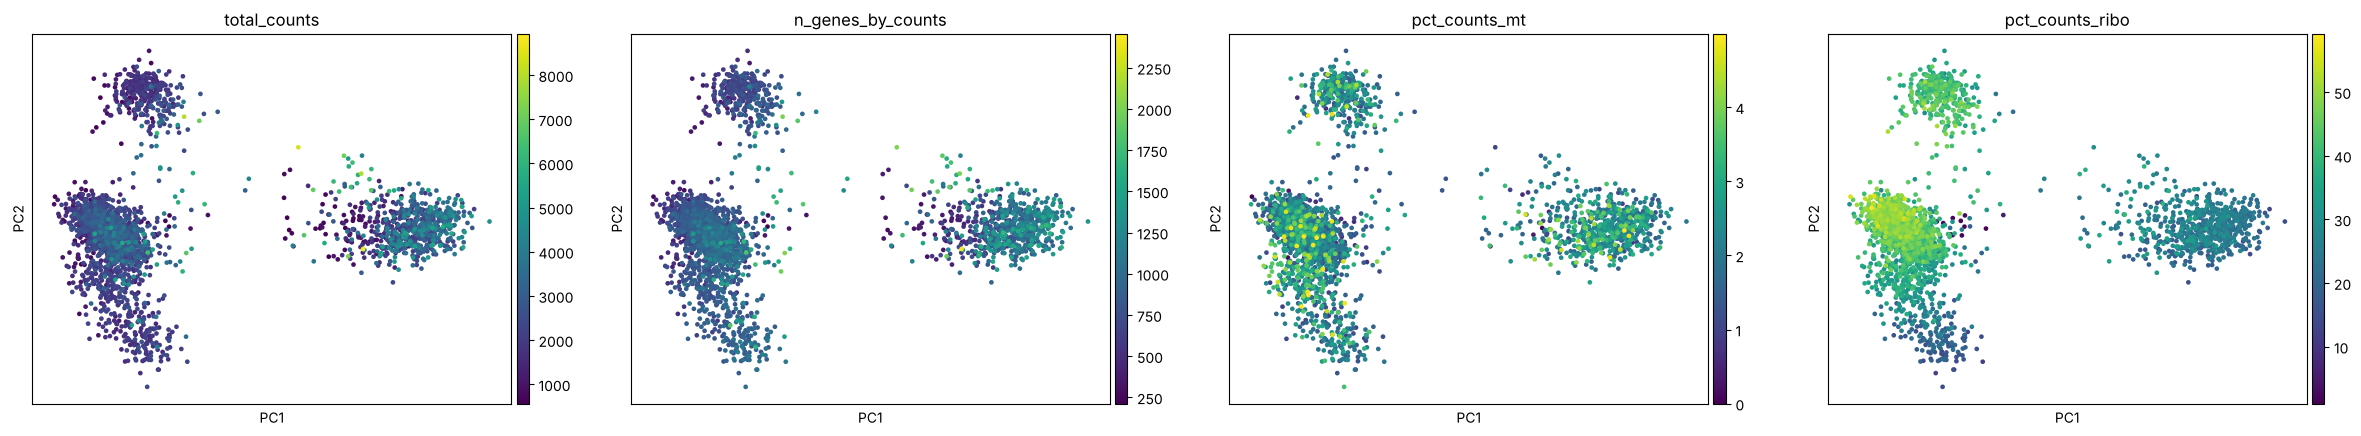

In [40]:
# Задание 5. Четыре варианта: (QC или нет) × (HVG или нет)
def run_variant(use_qc, use_hvg):
    ad = adata_qc.copy()                       # сырые данные + все QC-метрики из задания 1
    if use_qc:
        sc.pp.filter_cells(ad, min_genes=200)
        sc.pp.filter_genes(ad, min_cells=3)
        ad = ad[(ad.obs.n_genes_by_counts < 2500) & (ad.obs.pct_counts_mt < 5)].copy()
    ad.layers["counts"] = ad.X.copy()
    if use_hvg:
        sc.pp.highly_variable_genes(ad, layer="counts", flavor="seurat_v3", n_top_genes=2000)
    sc.pp.normalize_total(ad, target_sum=1e4)
    sc.pp.log1p(ad)
    sc.tl.pca(ad, mask_var="highly_variable" if use_hvg else None)
    return ad

variants = {
    "1) без QC, без HVG": run_variant(False, False),
    "2) без QC, с HVG": run_variant(False, True),
    "3) с QC, без HVG": run_variant(True, False),
    "4) с QC, с HVG": run_variant(True, True),
}
qc_color = ["total_counts", "n_genes_by_counts", "pct_counts_mt", "pct_counts_ribo"]
for name, ad in variants.items():
    print(name, "— клеток:", ad.n_obs)
    sc.pl.pca(ad, color=qc_color, ncols=4, cmap="viridis")

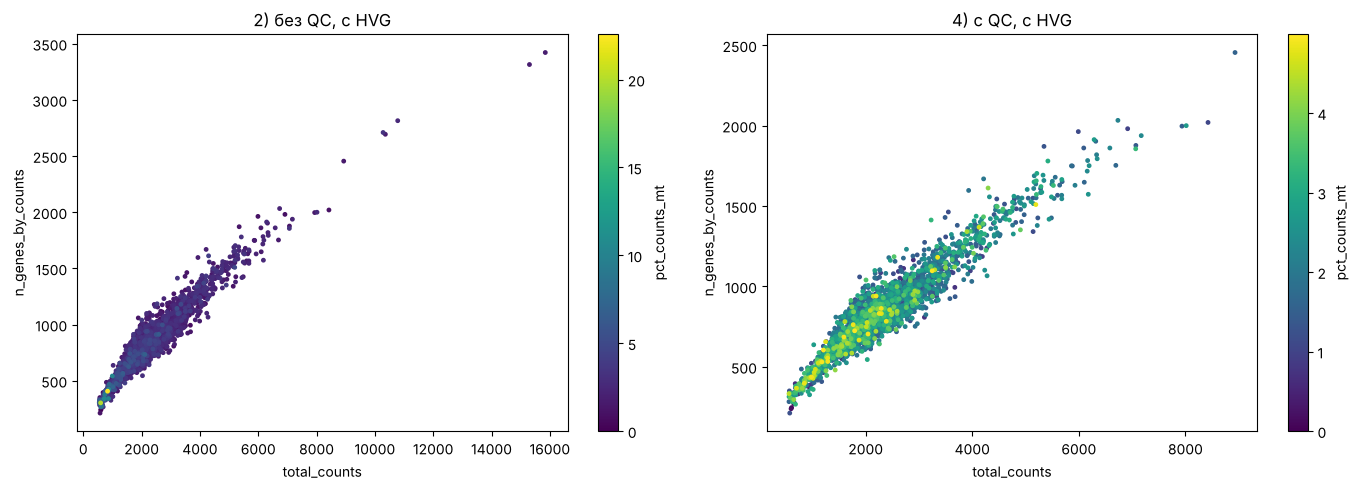

In [41]:
# scatter total_counts vs n_genes_by_counts, цвет — pct_counts_mt
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, name in zip(axes, ["2) без QC, с HVG", "4) с QC, с HVG"]):
    o = variants[name].obs.sort_values("pct_counts_mt")
    s = ax.scatter(o.total_counts, o.n_genes_by_counts, c=o.pct_counts_mt, s=6, cmap="viridis")
    plt.colorbar(s, ax=ax, label="pct_counts_mt")
    ax.set_title(name); ax.set_xlabel("total_counts"); ax.set_ylabel("n_genes_by_counts")
plt.tight_layout(); plt.show()

In [42]:
# насколько PC1/PC2 связаны с QC-метриками (корреляция Спирмена, по модулю)
rows = []
for name, ad in variants.items():
    for k in [0, 1]:
        row = {"вариант": name, "PC": f"PC{k+1}"}
        for m in qc_color:
            row[m] = round(abs(spearmanr(ad.obsm["X_pca"][:, k], ad.obs[m])[0]), 2)
        rows.append(row)
pd.DataFrame(rows)

,вариант,PC,total_counts,n_genes_by_counts,pct_counts_mt,pct_counts_ribo
0,"1) без QC, без HVG",PC1,0.15,0.34,0.16,0.83
1,"1) без QC, без HVG",PC2,0.35,0.55,0.05,0.34
2,"2) без QC, с HVG",PC1,0.27,0.38,0.09,0.66
3,"2) без QC, с HVG",PC2,0.08,0.27,0.04,0.32
4,"3) с QC, без HVG",PC1,0.15,0.34,0.17,0.83
5,"3) с QC, без HVG",PC2,0.30,0.51,0.03,0.35
6,"4) с QC, с HVG",PC1,0.24,0.36,0.13,0.68
7,"4) с QC, с HVG",PC2,0.07,0.26,0.04,0.34


### Выводы и ответы

**1. Связано ли положение клеток с числом UMI?** Немного: корреляция PC1 с `total_counts` 0.15–0.27, с числом генов 0.34–0.38. Отчасти это биология: у моноцитов больше РНК, чем у лимфоцитов. Без QC между группами видны несколько клеток с 10–16 тыс. UMI — это дублеты, после QC их нет.

**2. Есть ли направление, вдоль которого меняется доля mt?** Нет, корреляция с PC1 и PC2 ≤ 0.17. После QC (`pct_counts_mt` < 5%) митохондриальные гены почти не влияют на PCA.

**3. Влияют ли технические факторы?**
- Сильнее всего с PC1 связана доля рибосомных UMI (0.66–0.83), но это биология: PC1 отделяет моноциты от лимфоцитов.
- Без HVG PC2 сильнее связана с числом генов (0.51–0.55 против 0.26–0.27 с HVG), то есть в компоненты влезает глубина. HVG это снижают.
- QC почти не меняет картинку: плохих клеток мало (62 из 2700).



## Задание 6. Какие гены формируют главные компоненты?

PCA строит новые признаки как линейные комбинации исходных генов.

Для первой компоненты:

$$
PC_1=a_1Z_1+a_2Z_2+\ldots+a_nZ_n
$$

Коэффициенты $a_i$ называются *loadings*.

Получите 10 генов с наибольшими положительными и 10 с наиболее отрицательными loadings для PC1 и PC2.

Постройте график loadings и графики экспрессии нескольких найденных генов на PCA.

**Вопросы:** Какие гены сильнее всего определяют PC1 и PC2? Связаны ли они с иммунными клеточными популяциями, клеточным циклом или QC-метриками? Можно ли биологически интерпретировать главные компоненты на основании этих генов?

In [43]:
# Задание 6. Loadings PC1 и PC2 (основной анализ: QC + 2000 HVG)
loadings = pd.DataFrame(adata.varm["PCs"][:, :2], index=adata.var_names, columns=["PC1", "PC2"])
loadings = loadings[adata.var["highly_variable"]]
for pc in ["PC1", "PC2"]:
    s = loadings[pc].sort_values()
    print(f"{pc}: 10 самых положительных:", list(s.index[-10:][::-1]))
    print(f"{pc}: 10 самых отрицательных:", list(s.index[:10]))

PC1: 10 самых положительных: ['LYZ', 'CST3', 'S100A9', 'TYROBP', 'S100A8', 'LGALS1', 'AIF1', 'LST1', 'FCER1G', 'FCN1']
PC1: 10 самых отрицательных: ['LTB', 'IL32', 'MALAT1', 'IL7R', 'CCL5', 'CD2', 'CTSW', 'STK17A', 'ACAP1', 'CD247']
PC2: 10 самых положительных: ['HLA-DRA', 'CD74', 'HLA-DPB1', 'HLA-DRB1', 'CD79A', 'HLA-DPA1', 'HLA-DQA1', 'HLA-DQB1', 'CD79B', 'HLA-DRB5']
PC2: 10 самых отрицательных: ['NKG7', 'S100A4', 'CCL5', 'IL32', 'GNLY', 'CTSW', 'GZMA', 'CST7', 'SRGN', 'ANXA1']


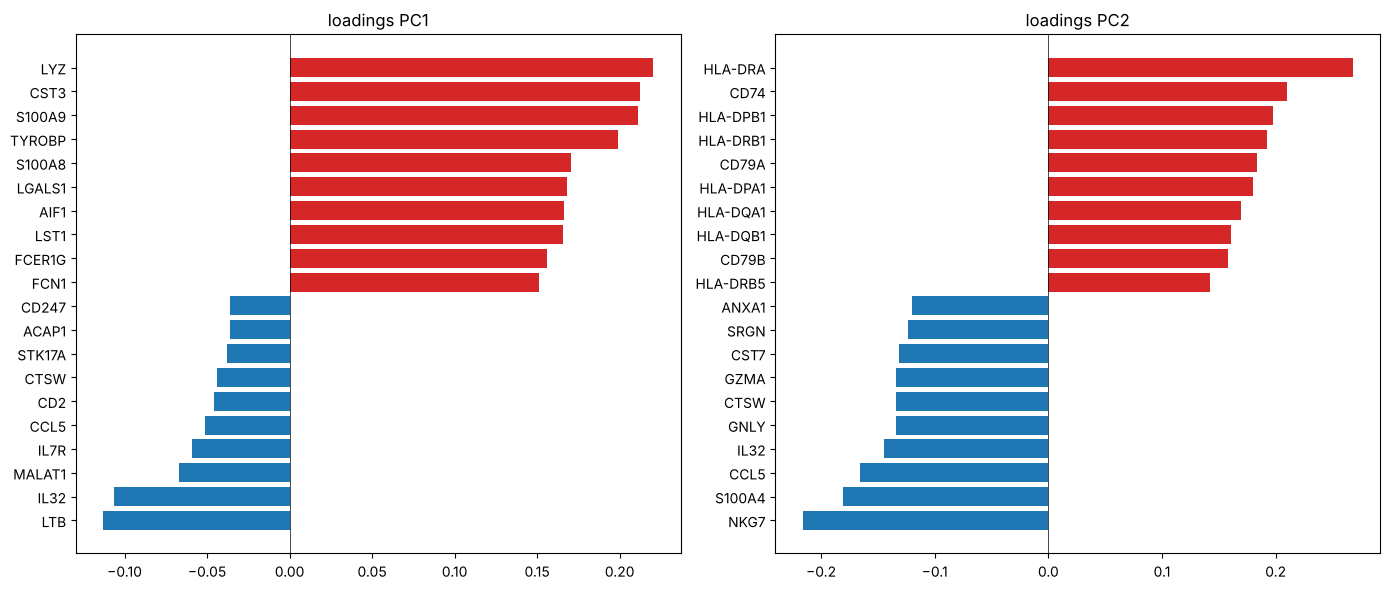

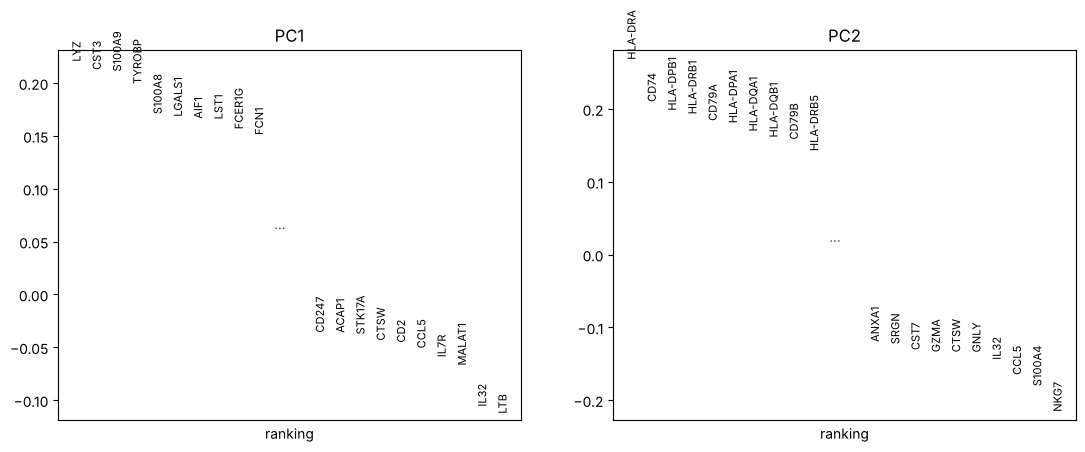

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, pc in zip(axes, ["PC1", "PC2"]):
    s = loadings[pc].sort_values()
    top = pd.concat([s.head(10), s.tail(10)])
    ax.barh(top.index, top.values, color=["tab:blue"] * 10 + ["tab:red"] * 10)
    ax.set_title(f"loadings {pc}"); ax.axvline(0, color="k", lw=0.5)
plt.tight_layout(); plt.show()

sc.pl.pca_loadings(adata, components=[1, 2], n_points=20)

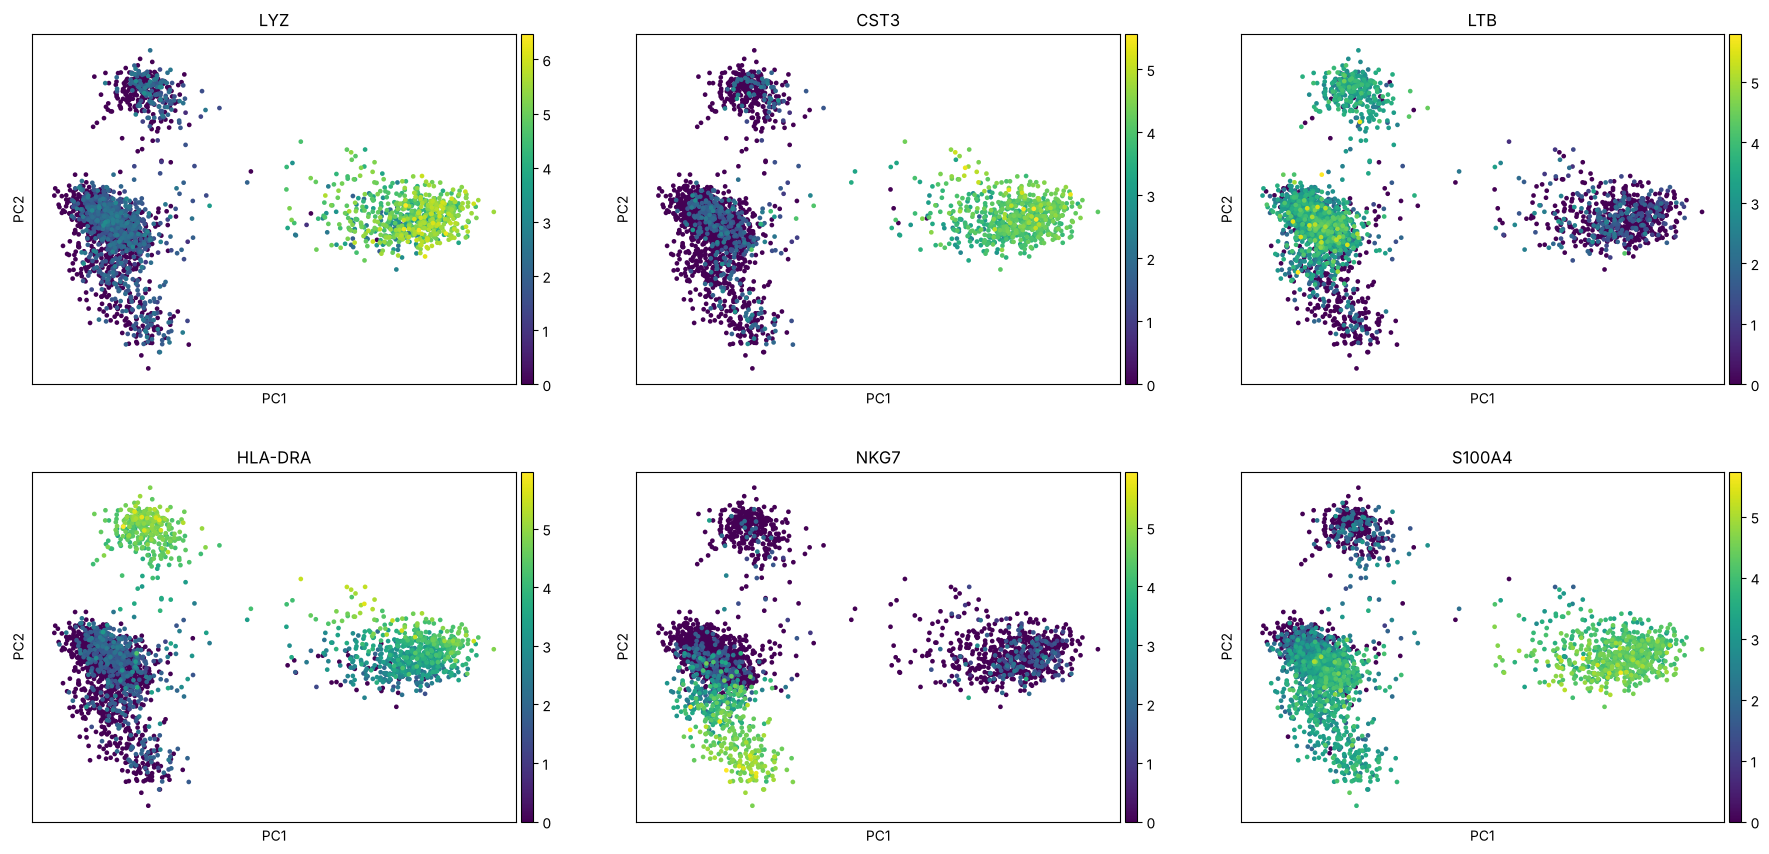

PC1: {'total_counts': np.float64(0.24), 'pct_counts_mt': np.float64(0.13), 'pct_counts_ribo': np.float64(-0.68)}
PC2: {'total_counts': np.float64(-0.07), 'pct_counts_mt': np.float64(-0.04), 'pct_counts_ribo': np.float64(0.34)}


In [45]:
# экспрессия нескольких найденных генов на PCA
s1, s2 = loadings["PC1"].sort_values(), loadings["PC2"].sort_values()
show_genes = [s1.index[-1], s1.index[-2], s1.index[0], s2.index[-1], s2.index[0], s2.index[1]]
sc.pl.pca(adata, color=show_genes, ncols=3)
# связь PC1/PC2 с QC-метриками в основном анализе
for k in [0, 1]:
    print(f"PC{k+1}:", {m: round(spearmanr(adata.obsm['X_pca'][:, k], adata.obs[m])[0], 2)
                        for m in ["total_counts", "pct_counts_mt", "pct_counts_ribo"]})

### Выводы и ответы

**1. Какие гены определяют PC1 и PC2?**
- PC1 +: `LYZ`, `CST3`, `S100A9`, `TYROBP`, `S100A8`, `LST1`, `FCN1` — моноциты; PC1 −: `LTB`, `IL32`, `IL7R`, `CD2`, `CCL5`, `CD247` — T-клетки.
- PC2 +: `HLA-DRA`, `CD74`, `HLA-DP*`, `HLA-DQ*`, `CD79A`, `CD79B` — B-клетки; PC2 −: `NKG7`, `GNLY`, `GZMA`, `CST7`, `CTSW` — NK и CD8 T.

**2. Связаны ли они с типами клеток, циклом или QC?** С иммунными популяциями. Генов цикла (`MKI67`, `TOP2A`) и `MT-` в топе нет, из технических — только `MALAT1`. С QC связь слабая (`total_counts` с PC1 — 0.24, `pct_counts_mt` — 0.13).

**3. Можно ли интерпретировать компоненты?** Да. PC1 — моноциты против лимфоцитов, PC2 — B-клетки против NK/цитотоксических клеток. Это видно и на графиках: `LYZ` и `CST3` горят справа, `HLA-DRA` сверху, `NKG7` снизу.


## Задание 7
- Постройте график PCA не используя логарифмирование log1p
- Постройте график PCA не используя логарифмирование log1p и нормализацию normalize
- Попробуйте дополнительно к нормализации и логарифмированию использовать `sc.pp.scale(adata)`

`sc.pp.scale(adata)` делает стандартизацию генов по столбцам клеток. 

**Вопросы:** Что сильнее влияет на PCA - нормализация или логарифмирование? Сильно ли помогает scale? Что нам даёт каждая процедура: логарифмирование, нормализация, стандартизация; как они влияют на PCA? Все ли их нужно делать перед PCA?

/usr/local/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


raw counts (без norm и log)


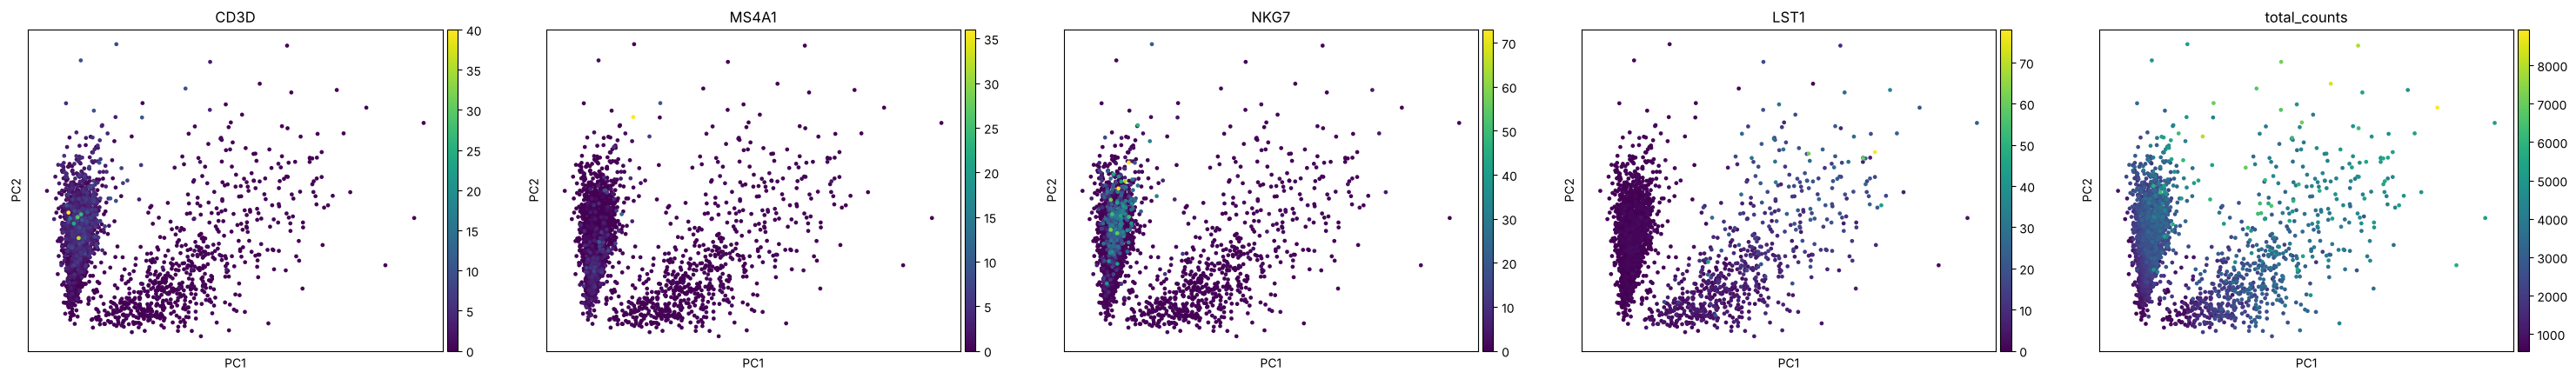

только log1p (без norm)


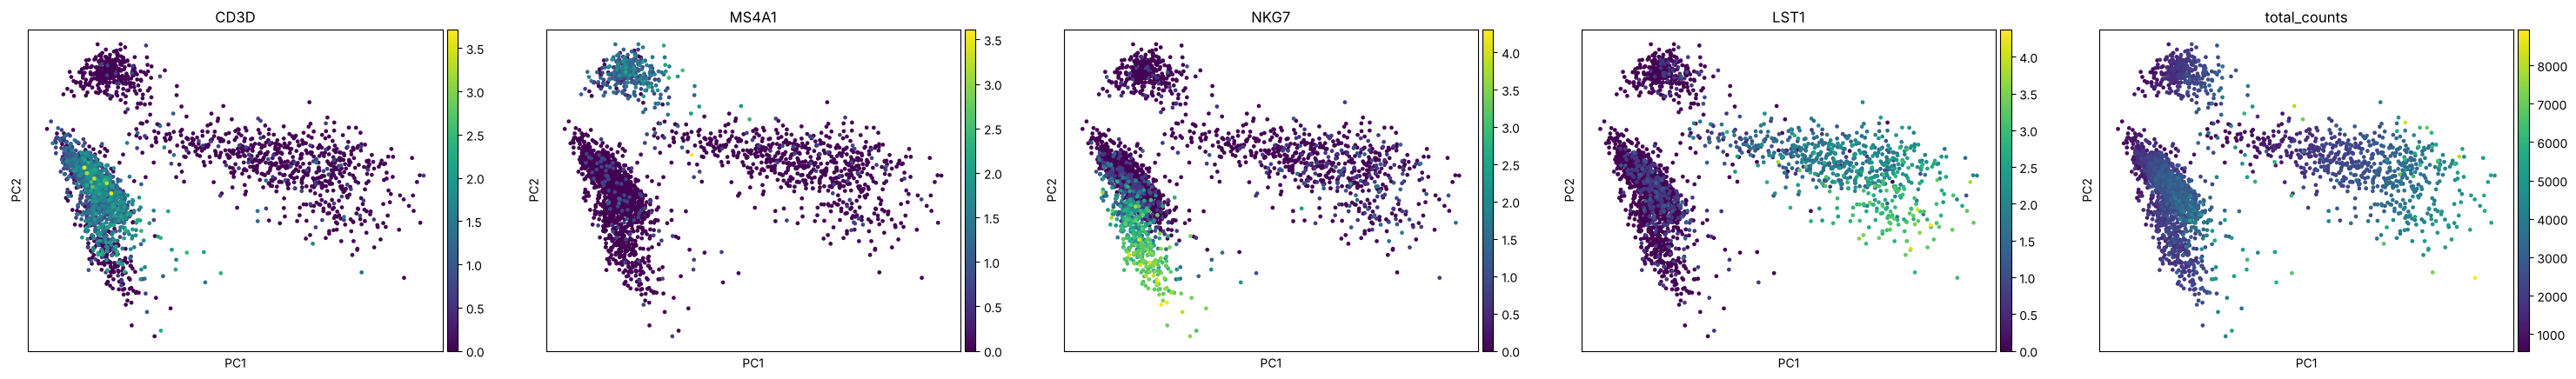

только normalize (без log)


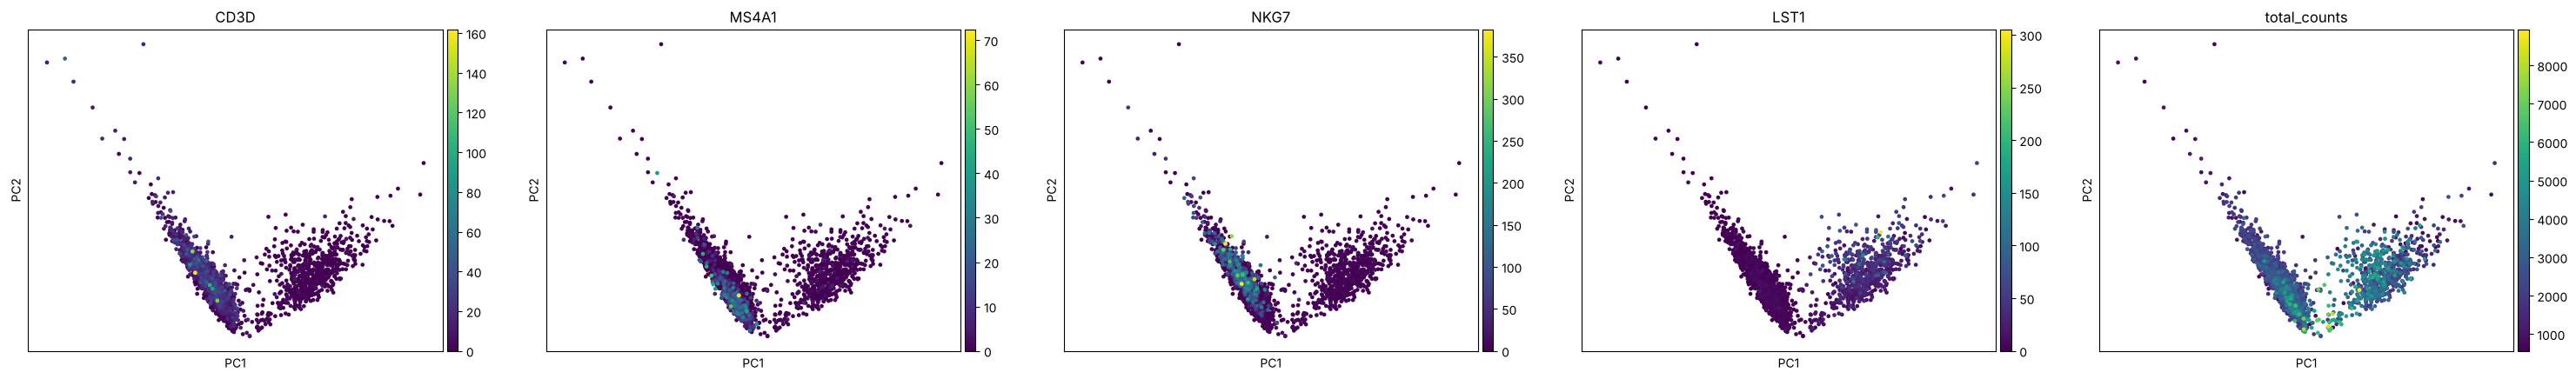

normalize + log1p (как на занятии)


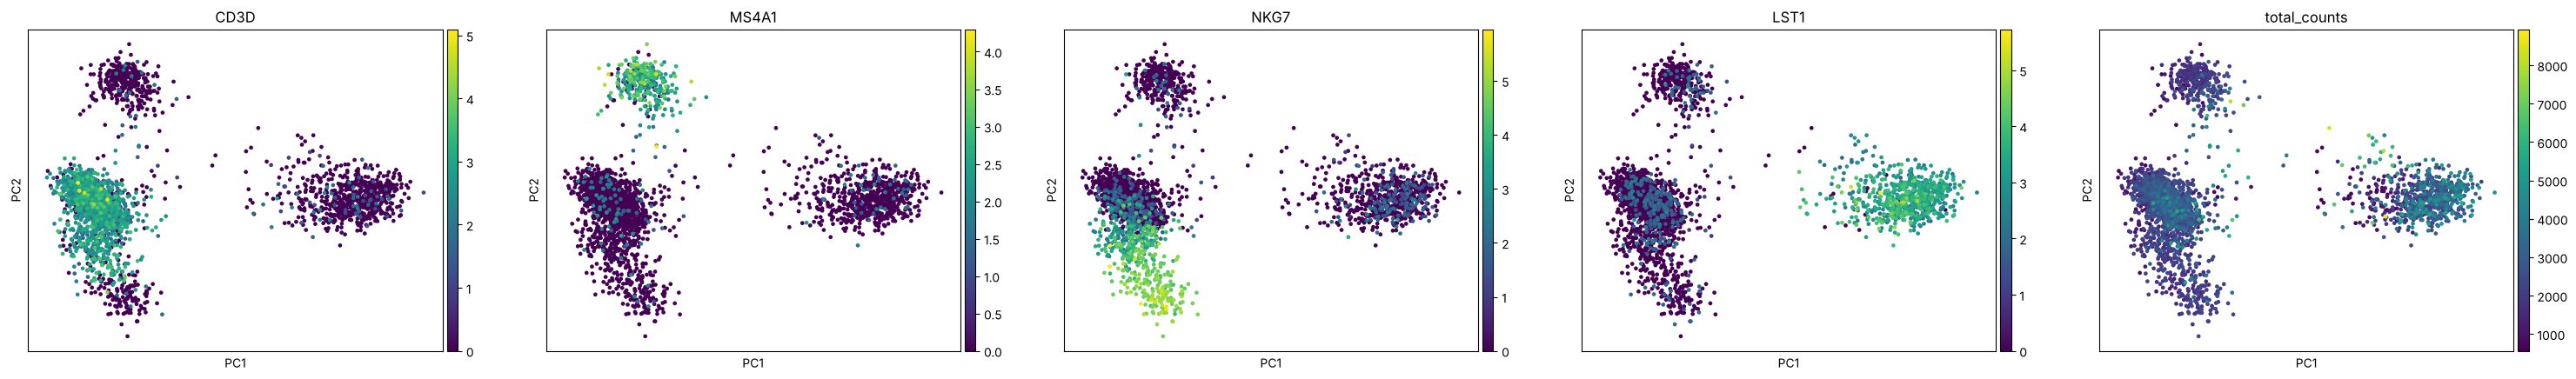

normalize + log1p + scale


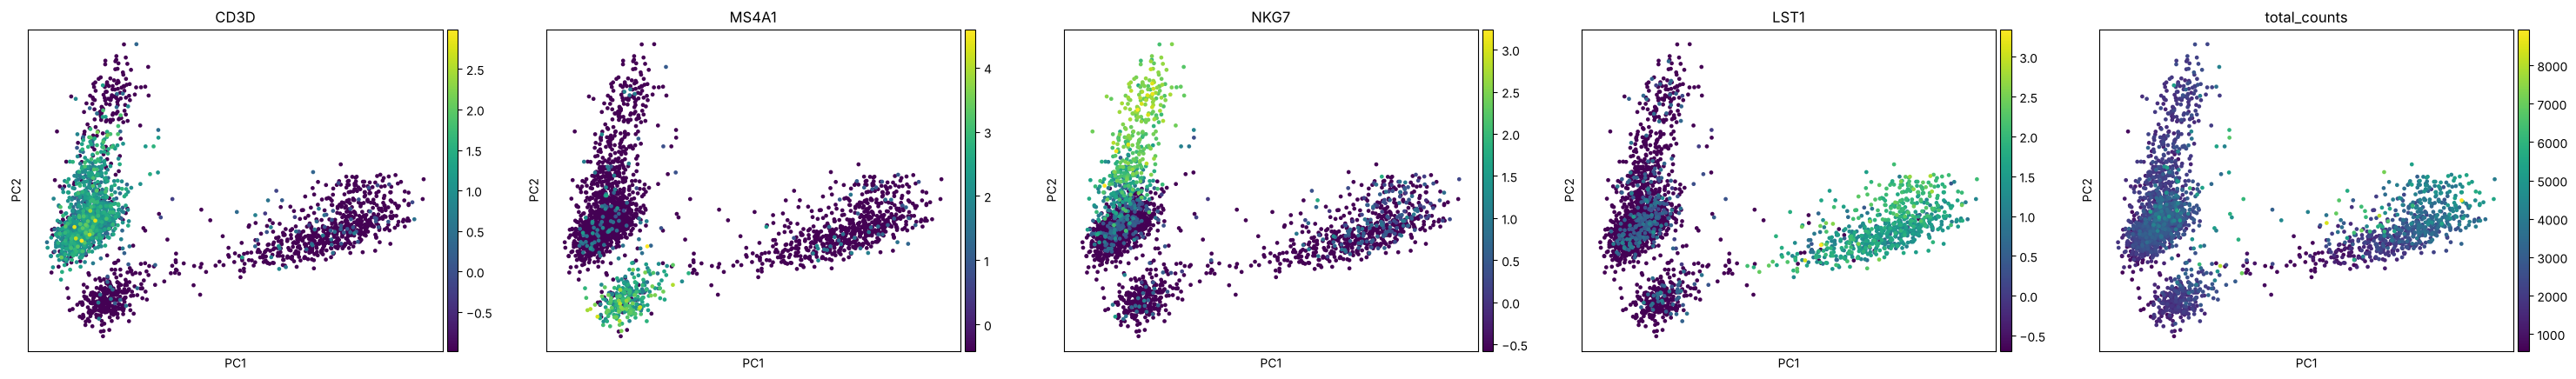

In [46]:
# Задание 7. Влияние нормализации, логарифмирования и scale на PCA
def pca_variant(normalize, log, scale):
    ad = adata.copy()
    ad.X = ad.layers["counts"].copy().astype(np.float32)   # начинаем с сырых counts
    ad.uns.pop("log1p", None)                               # чтобы scanpy не думал, что X уже логарифмирован
    if normalize:
        sc.pp.normalize_total(ad, target_sum=1e4)
    if log:
        sc.pp.log1p(ad)
    if scale:
        sc.pp.scale(ad, max_value=10)
    sc.tl.pca(ad, mask_var="highly_variable")
    return ad

pca7 = {
    "raw counts (без norm и log)": pca_variant(False, False, False),
    "только log1p (без norm)": pca_variant(False, True, False),
    "только normalize (без log)": pca_variant(True, False, False),
    "normalize + log1p (как на занятии)": pca_variant(True, True, False),
    "normalize + log1p + scale": pca_variant(True, True, True),
}
for name, ad in pca7.items():
    print(name)
    sc.pl.pca(ad, color=markers + ["total_counts"], ncols=5, cmap="viridis")

In [47]:
rows = []
for name, ad in pca7.items():
    vr = ad.uns["pca"]["variance_ratio"]
    l1 = pd.Series(ad.varm["PCs"][:, 0], index=ad.var_names).abs().sort_values(ascending=False)
    rows.append({"вариант": name,
                 "PC1, % дисп.": round(vr[0] * 100, 1),
                 "PC1-10, %": round(vr[:10].sum() * 100, 1),
                 "|r| PC1 ~ total_counts": round(abs(spearmanr(ad.obsm["X_pca"][:, 0], ad.obs.total_counts)[0]), 2),
                 "доля PC1 от топ-3 генов": round((l1.head(3)**2).sum(), 2),
                 "топ-3 гена PC1": ", ".join(l1.index[:3])})
pd.DataFrame(rows)

,вариант,"PC1, % дисп.","PC1-10, %",|r| PC1 ~ total_counts,доля PC1 от топ-3 генов,топ-3 гена PC1
0,raw counts (без norm и log),44.099998,82.099998,0.49,0.75,"FTL, FTH1, TMSB4X"
1,только log1p (без norm),18.700001,32.599998,0.50,0.15,"LYZ, FTL, CST3"
2,только normalize (без log),39.400002,75.599998,0.27,0.78,"FTL, MALAT1, FTH1"
3,normalize + log1p (как на занятии),10.000000,19.700001,0.24,0.14,"LYZ, CST3, S100A9"
4,normalize + log1p + scale,2.900000,7.600000,0.29,0.05,"CST3, TYROBP, LST1"


### Выводы и ответы

- **Сырые counts** и **только normalize** — PC1 на 75–78% определяют 3 гена (`FTL`, `FTH1`, `TMSB4X`/`MALAT1`), B и NK не выделяются.
- **Только log1p** — группы видны почти как обычно, но PC1 сильнее связана с `total_counts` (0.50 против 0.24).
- **normalize + log1p** — группы разделены хорошо, связь с глубиной меньше всего.
- **+ scale** — группы те же, PC1 объясняет 2.9%: вклад распределён по многим генам.

**1. Что сильнее влияет — нормализация или логарифм?** Логарифм. Без него PCA определяют несколько самых экспрессируемых генов, а без нормализации группы видны, только примешивается глубина.

**2. Сильно ли помогает scale?** Немного: группы те же, NK и B отделяются чуть чище.

**3. Что даёт каждая процедура?**
- нормализация (CP10K) — убирает разную глубину секвенирования;
- логарифм — одинаковое кратное изменение даёт одинаковую разницу, сильно экспрессированные гены перестают доминировать;
- scale — у каждого гена среднее 0 и дисперсия 1, все гены весят одинаково.

**4. Всё ли нужно перед PCA?** Нормализацию и логарифм — да. Scale желателен, но не обязателен. При scale надо обрезать выбросы (`max_value=10`).


## Дополнительное задание. Клеточный цикл и PCA

Используйте наборы генов фаз S и G2/M, чтобы вычислить оценки активности программ клеточного цикла для каждой клетки.

Определите предполагаемую фазу клеточного цикла и постройте PCA, окрашенный по:

- `S_score`
- `G2M_score`
- `phase`

**Вопросы:** Разделяются ли клетки по фазам клеточного цикла? Можно ли обнаружить связь клеточного цикла с PC1 или PC2? Почему клетки одного типа могут отличаться по экспрессии генов клеточного цикла?

S генов в данных: 36 из 43 | G2M: 44 из 54
phase
G1     1685
S       866
G2M      87
Name: count, dtype: int64
        S_score  G2M_score
count  2638.000   2638.000
mean     -0.014     -0.088
std       0.050      0.050
min      -0.115     -0.211
25%      -0.049     -0.122
50%      -0.024     -0.093
75%       0.011     -0.058
max       0.593      0.735
клеток с G2M_score > 0.2: 3 | с S_score > 0.2: 8


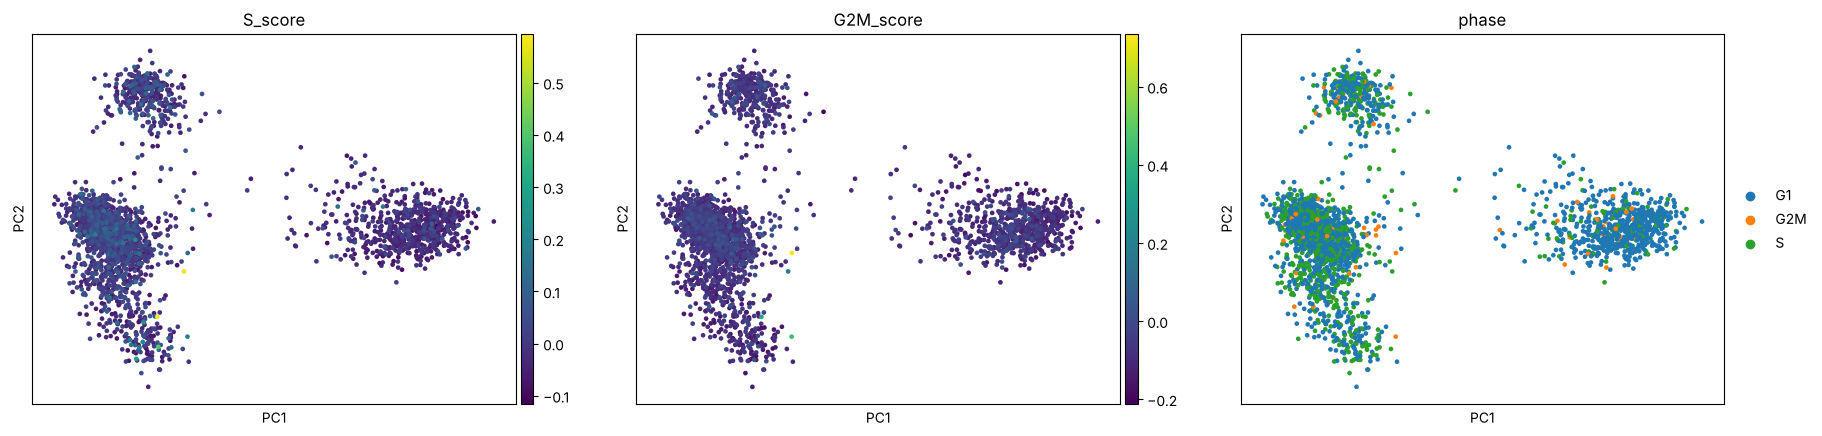

In [48]:
# Дополнительное задание. Клеточный цикл (списки генов Tirosh et al. 2016 / Seurat cc.genes, имена hg19)
s_genes = ["MCM5", "PCNA", "TYMS", "FEN1", "MCM2", "MCM4", "RRM1", "UNG", "GINS2", "MCM6", "CDCA7", "DTL",
           "PRIM1", "UHRF1", "MLF1IP", "HELLS", "RFC2", "RPA2", "NASP", "RAD51AP1", "GMNN", "WDR76", "SLBP",
           "CCNE2", "UBR7", "POLD3", "MSH2", "ATAD2", "RAD51", "RRM2", "CDC45", "CDC6", "EXO1", "TIPIN",
           "DSCC1", "BLM", "CASP8AP2", "USP1", "CLSPN", "POLA1", "CHAF1B", "BRIP1", "E2F8"]
g2m_genes = ["HMGB2", "CDK1", "NUSAP1", "UBE2C", "BIRC5", "TPX2", "TOP2A", "NDC80", "CKS2", "NUF2", "CKS1B",
             "MKI67", "TMPO", "CENPF", "TACC3", "FAM64A", "SMC4", "CCNB2", "CKAP2L", "CKAP2", "AURKB", "BUB1",
             "KIF11", "ANP32E", "TUBB4B", "GTSE1", "KIF20B", "HJURP", "CDCA3", "HN1", "CDC20", "TTK", "CDC25C",
             "KIF2C", "RANGAP1", "NCAPD2", "DLGAP5", "CDCA2", "CDCA8", "ECT2", "KIF23", "HMMR", "AURKA", "PSRC1",
             "ANLN", "LBR", "CKAP5", "CENPE", "CTCF", "NEK2", "G2E3", "GAS2L3", "CBX5", "CENPA"]
s_in = [g for g in s_genes if g in adata.var_names]
g2m_in = [g for g in g2m_genes if g in adata.var_names]
print("S генов в данных:", len(s_in), "из", len(s_genes), "| G2M:", len(g2m_in), "из", len(g2m_genes))

sc.tl.score_genes_cell_cycle(adata, s_genes=s_in, g2m_genes=g2m_in, random_state=0)
print(adata.obs["phase"].value_counts())
print(adata.obs[["S_score", "G2M_score"]].describe().round(3))
print("клеток с G2M_score > 0.2:", (adata.obs.G2M_score > 0.2).sum(), "| с S_score > 0.2:", (adata.obs.S_score > 0.2).sum())
sc.pl.pca(adata, color=["S_score", "G2M_score", "phase"], ncols=3, cmap="viridis")

In [49]:
for k in [0, 1]:
    print(f"PC{k+1}:", {m: round(spearmanr(adata.obsm['X_pca'][:, k], adata.obs[m])[0], 2)
                        for m in ["S_score", "G2M_score"]})
# где сидят клетки с самым высоким G2M_score — по маркерам
top_cycling = adata.obs.sort_values("G2M_score", ascending=False).head(20).index
print("\nСредняя экспрессия маркеров у 20 клеток с max G2M_score и у всех клеток:")
pd.DataFrame({"top-20 G2M": adata[top_cycling, markers + ["MKI67", "TOP2A"]].X.toarray().mean(0),
              "все клетки": adata[:, markers + ["MKI67", "TOP2A"]].X.toarray().mean(0)},
             index=markers + ["MKI67", "TOP2A"]).round(2)

PC1: {'S_score': np.float64(-0.23), 'G2M_score': np.float64(-0.05)}
PC2: {'S_score': np.float64(-0.01), 'G2M_score': np.float64(0.03)}

Средняя экспрессия маркеров у 20 клеток с max G2M_score и у всех клеток:


,top-20 G2M,все клетки
CD3D,0.85,1.26
MS4A1,0.74,0.35
NKG7,1.05,0.90
LST1,0.72,0.98
MKI67,0.25,0.00
TOP2A,0.18,0.00


### Выводы и ответы

**1. Разделяются ли клетки по фазам?** Нет, `phase` перемешан по всем группам. Почти все оценки около 0: только 3 клетки с `G2M_score` > 0.2 и 8 с `S_score` > 0.2. Метка S у 866 клеток — в основном шум, потому что фаза ставится по знаку маленькой оценки. PBMC — покоящиеся клетки, они почти не делятся.

**2. Связь с PC1 или PC2?** С `G2M_score` связи нет (|r| ≤ 0.05), у `S_score` с PC1 слабая связь (−0.23). У 20 клеток с максимальным `G2M_score` есть `MKI67` и `TOP2A` — это редкие делящиеся клетки.

**3. Почему клетки одного типа отличаются по генам цикла?** Они могут быть в разных фазах: одна покоится, другая делится (активированные лимфоциты). Эту вариацию можно убрать через `regress_out` по `S_score` и `G2M_score`.
